# Predictive Analysis of Developer Compensation and AI-Tool Adoption
### Stack Overflow Annual Developer Survey 2024 — CA2 Predictive Analysis Project

**Notebook map** — Part A: setup & data inspection · Part B: data-quality assessment & cleaning ·
Part C: EDA · Part D: Objectives O1–O5 (statistical analysis) · Part E: Objectives O6–O7 (machine
learning) · Part F: Objective O8 (explainability & error analysis) · Part G: conclusions.

**How to run:** `jupyter nbconvert --to notebook --execute --inplace notebooks/CA2_Predictive_Analysis.ipynb`
(about 15–25 minutes on a single CPU core; every random process uses `RANDOM_STATE = 42`).

---
## Project objectives (defined *before* any modelling)
| # | Objective (measurable) | Method | Success measure |
|---|---|---|---|
| **O1** | Quantify how much **country** explains developer pay and where India sits | Kruskal–Wallis, η², Mann–Whitney + Holm, bootstrap CIs | η² / R² of country; India:USA median ratio with 95 % CI |
| **O2** | Quantify the **experience → pay** relationship and its diminishing returns | Spearman ρ, log-linear quadratic OLS, bootstrap | ρ with CI; % pay gain per year at 0/5/10/20 yrs; India vs USA slope test |
| **O3** | Estimate **net** effects of role, work mode, company size and education after controlling for country & experience | OLS (HC3 robust), nested-model ΔR², partial η² | Adjusted % differences with 95 % CIs; ΔR² per block |
| **O4** | Map **who uses AI tools** in development (current adoption) | χ² tests, Cramér's V, Wilson CIs, two-proportion z-test | Adoption rate per group; V ranking; India vs world gap |
| **O5** | Understand AI **sentiment, trust and job-threat** perception across career stages | Spearman/Kruskal, χ², Cramér's V | ρ (experience ↔ trust), threat-rate gaps by role |
| **O6** | **Predict annual compensation** (regression, ≥ 4 models) | Baselines, Ridge, RF, HGB, LightGBM + CV + tuning | RMSE(log) ↓ ≥ 40 % vs global-median baseline; R², MAE (USD), MdAPE |
| **O7** | **Predict current AI-tool adoption** (classification, ≥ 4 models) | LogReg, RF, HGB, LightGBM + CV + tuning | ROC-AUC, F1, precision/recall vs majority baseline |
| **O8** | **Explain** the models and audit their errors | Permutation importance, SHAP, PDP, residuals by segment | Top drivers; error gaps across countries/segments |

In [1]:
import warnings, json, sys, time, platform
from pathlib import Path
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import sklearn, statsmodels, lightgbm, scipy, joblib
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_validate, cross_val_predict

from src.config import *
from src.data_prep import *
from src.features import *
from src.modeling import *
from src.stats_utils import *
from src.plotting import (set_style, savefig, save_table, reset_registry, PALETTE, CAT, SEQ5)

set_style(); reset_registry()
pd.set_option("display.max_columns", 60, "display.width", 160, "display.float_format", "{:,.3f}".format)
R = {}            # master results dictionary -> reports/results/results.json (feeds the written report)

def save_results():
    def default(o):
        if isinstance(o, (np.integer,)): return int(o)
        if isinstance(o, (np.floating,)): return float(o)
        if isinstance(o, (np.ndarray,)): return o.tolist()
        if isinstance(o, pd.DataFrame): return o.to_dict("records")
        return str(o)
    (RES_DIR / "results.json").write_text(json.dumps(R, indent=1, default=default))

R["environment"] = dict(python=platform.python_version(), pandas=pd.__version__, numpy=np.__version__,
                        scipy=scipy.__version__, sklearn=sklearn.__version__, statsmodels=statsmodels.__version__,
                        lightgbm=lightgbm.__version__, seed=RANDOM_STATE)
print(R["environment"])

{'python': '3.12.3', 'pandas': '3.0.2', 'numpy': '2.4.4', 'scipy': '1.17.1', 'sklearn': '1.8.0', 'statsmodels': '0.15.0', 'lightgbm': '4.7.0', 'seed': 42}


# Part A — Data inspection
**Source:** Stack Overflow Annual Developer Survey 2024 (fielded May 2024, > 65 000 developers), distributed by
Stack Overflow at <https://survey.stackoverflow.co/> under the Open Database Licence (ODbL).
The *single-response, integer-coded* extract and its crosswalk were curated by Havisha Khurana for the
**TidyTuesday** project (week 36 of 2024) and are stored in the public GitHub repository
`rfordatascience/tidytuesday` (`data/2024/2024-09-03/`). Files in `data/raw/` are byte-for-byte copies
(SHA-256 checksums are in `data/DATASET_DOCUMENTATION.md`).

In [2]:
df_raw, crosswalk, questions = load_raw()
print("Raw survey table:", df_raw.shape, "| crosswalk rows:", crosswalk.shape, "| questions:", questions.shape)
R["dataset"] = dict(rows=len(df_raw), cols=df_raw.shape[1], n_countries=int(df_raw.country.nunique()),
                    n_questions=len(questions), memory_mb=float(df_raw.memory_usage(deep=True).sum() / 1e6))
df_raw.head()

Raw survey table: (65437, 28) | crosswalk rows: (122, 3) | questions: (24, 2)


,response_id,main_branch,age,remote_work,ed_level,years_code,years_code_pro,dev_type,org_size,purchase_influence,buildvs_buy,country,currency,comp_total,so_visit_freq,so_account,so_part_freq,so_comm,ai_select,ai_sent,ai_acc,ai_complex,ai_threat,survey_length,survey_ease,converted_comp_yearly,r_used,r_want_to_use
0,1,1,8,3.000,4.000,NaN,NaN,NaN,NaN,NaN,NaN,United States of America,NaN,NaN,NaN,NaN,NaN,NaN,3.000,5.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,1,3,3.000,2.000,20.000,17.000,16.000,NaN,NaN,NaN,United Kingdom of Great Britain and Northern I...,NaN,NaN,5.000,3.000,6.000,5.000,1.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000,0.000
2,3,1,4,3.000,3.000,37.000,27.000,10.000,NaN,NaN,NaN,United Kingdom of Great Britain and Northern I...,NaN,NaN,5.000,3.000,6.000,5.000,1.000,NaN,NaN,NaN,NaN,1.000,2.000,NaN,0.000,0.000
3,4,2,1,NaN,7.000,4.000,NaN,16.000,NaN,NaN,NaN,Canada,NaN,NaN,3.000,1.000,NaN,3.000,3.000,5.000,5.000,1.000,2.000,2.000,2.000,NaN,0.000,0.000
4,5,1,1,NaN,6.000,9.000,NaN,16.000,NaN,NaN,NaN,Norway,NaN,NaN,5.000,3.000,6.000,5.000,1.000,NaN,NaN,NaN,NaN,3.000,2.000,NaN,0.000,0.000


In [3]:
# Decode integer codes with the official crosswalk and add stateless engineered columns
df = add_features(decode(df_raw, crosswalk))
display(df[["response_id", "main_branch", "age", "country", "dev_type", "years_code_pro",
            "converted_comp_yearly", "ai_select"]].head())
print(df_raw.dtypes.value_counts())

,response_id,main_branch,age,country,dev_type,years_code_pro,converted_comp_yearly,ai_select
0,1,I am a developer by profession,<18,USA,NaN,NaN,NaN,Yes
1,2,I am a developer by profession,35-44,UK,Full-stack dev,17.000,NaN,"No, and I don't plan to"
2,3,I am a developer by profession,45-54,UK,Developer experience,27.000,NaN,"No, and I don't plan to"
3,4,I am learning to code,18-24,Canada,Full-stack dev,NaN,NaN,Yes
4,5,I am a developer by profession,18-24,Norway,Full-stack dev,NaN,NaN,"No, and I don't plan to"


float64    23
int64       3
str         2
Name: count, dtype: int64


### Data dictionary
`role` states how each column is used: **Target**, **Predictor**, **Analysis-only** (used in O4–O5 but excluded
from models to prevent leakage) or **Excluded**.

In [4]:
DD = [
 ("response_id","Respondent identifier","ID","Excluded"),
 ("main_branch","Professional coding level of respondent","Nominal (5)","Predictor (AI task) / filter"),
 ("age","Age bracket","Ordinal (8)","Predictor (as age_mid)"),
 ("remote_work","Current work situation (remote / hybrid / in-person)","Nominal (3)","Predictor"),
 ("ed_level","Highest formal education completed","Ordinal (8)","Predictor"),
 ("years_code","Total years coded (incl. education); >50 coded as 51","Numeric","Predictor"),
 ("years_code_pro","Years coded professionally; >50 coded as 51","Numeric","Predictor"),
 ("dev_type","Best description of current job","Nominal (34)","Predictor"),
 ("org_size","Number of people in the organisation","Ordinal (10)","Predictor"),
 ("purchase_influence","Influence over technology purchases","Ordinal (3)","Predictor"),
 ("buildvs_buy","Customisation needed in last tool recommendation","Nominal (3)","Predictor"),
 ("country","Country of residence","Nominal (≈185)","Predictor"),
 ("currency","Day-to-day currency","Nominal","Excluded (duplicates country)"),
 ("comp_total","Total annual compensation in local currency","Numeric","Excluded (target twin)"),
 ("so_visit_freq","Stack Overflow visit frequency","Ordinal (5)","Predictor"),
 ("so_account","Has a Stack Overflow account","Nominal (3)","Predictor"),
 ("so_part_freq","Stack Overflow Q&A participation frequency","Ordinal (6)","Predictor"),
 ("so_comm","Feels part of the Stack Overflow community","Ordinal (6)","Predictor"),
 ("ai_select","Currently uses AI tools in development","Ordinal (3)","Target (O7) / Predictor (O6)"),
 ("ai_sent","Stance on AI tools in workflow","Ordinal (6)","Analysis-only (conditional question)"),
 ("ai_acc","Trust in accuracy of AI output","Ordinal (5)","Analysis-only (conditional question)"),
 ("ai_complex","AI performance on complex tasks","Ordinal (5)","Analysis-only (conditional question)"),
 ("ai_threat","Believes AI is a threat to own job","Nominal (3)","Analysis-only (conditional question)"),
 ("survey_length","Opinion on survey length","Nominal (3)","Excluded"),
 ("survey_ease","Opinion on survey difficulty","Nominal (3)","Excluded"),
 ("converted_comp_yearly","Annual compensation converted to USD","Numeric","Target (O6)"),
 ("r_used","Used the R language last year (flag)","Binary","Predictor"),
 ("r_want_to_use","Wants to use R next year (flag)","Binary","Excluded (not relevant)"),
]
data_dict = pd.DataFrame(DD, columns=["variable", "description", "type", "role"])
data_dict["missing_%"] = data_dict["variable"].map(df_raw.isna().mean() * 100).round(1)
save_table(data_dict, "tbl_data_dictionary", "Data dictionary of the 28 raw survey variables", "EDA")
data_dict

,variable,description,type,role,missing_%
0,response_id,Respondent identifier,ID,Excluded,0.000
1,main_branch,Professional coding level of respondent,Nominal (5),Predictor (AI task) / filter,0.000
2,age,Age bracket,Ordinal (8),Predictor (as age_mid),0.000
3,remote_work,Current work situation (remote / hybrid / in-p...,Nominal (3),Predictor,16.200
4,ed_level,Highest formal education completed,Ordinal (8),Predictor,7.100
5,years_code,Total years coded (incl. education); >50 coded...,Numeric,Predictor,8.500
6,years_code_pro,Years coded professionally; >50 coded as 51,Numeric,Predictor,21.100
7,dev_type,Best description of current job,Nominal (34),Predictor,9.200
8,org_size,Number of people in the organisation,Ordinal (10),Predictor,27.400
9,purchase_influence,Influence over technology purchases,Ordinal (3),Predictor,27.600


# Part B — Data-quality assessment
We check (i) missing values, (ii) duplicates, (iii) logically inconsistent values and (iv) outliers —
in that order — and document every cleaning decision.

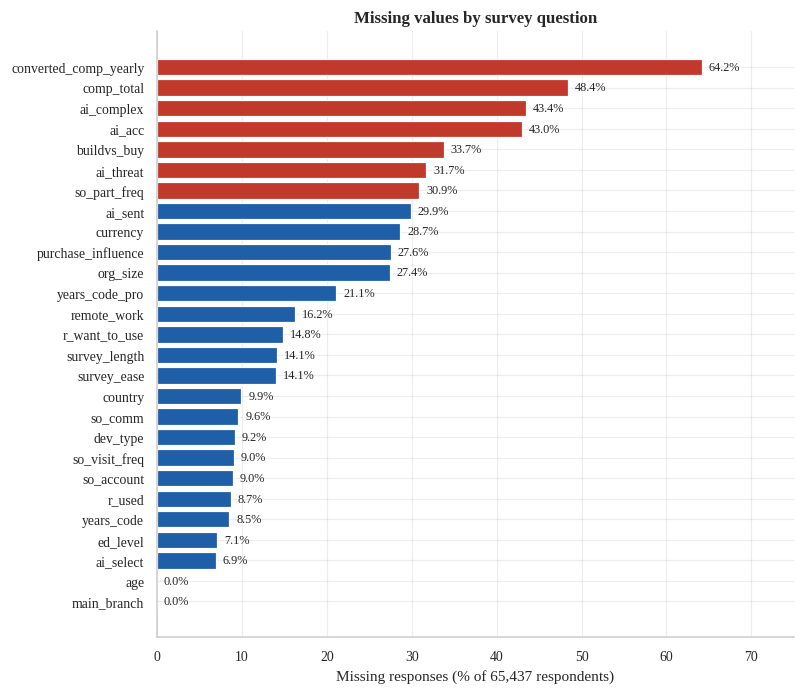

,missing_n,missing_pct,dtype,n_unique
converted_comp_yearly,42002,64.187,float64,6113
comp_total,31697,48.439,float64,3337
ai_complex,28416,43.425,float64,5
ai_acc,28135,42.996,float64,5
buildvs_buy,22079,33.741,float64,3
ai_threat,20748,31.707,float64,3
so_part_freq,20200,30.869,float64,6
ai_sent,19564,29.897,float64,6


In [5]:
mt = missing_table(df_raw.drop(columns="response_id"))
save_table(mt.reset_index().rename(columns={"index": "variable"}), "tbl_missing", "Missing values per variable", "EDA")
R["missing"] = dict(worst=mt.head(6)[["missing_pct"]].round(1).to_dict()["missing_pct"],
                    overall_cell_pct=float(df_raw.drop(columns="response_id").isna().mean().mean() * 100))
fig, ax = plt.subplots(figsize=(7.2, 6.2))
m = mt.sort_values("missing_pct")
ax.barh(m.index, m["missing_pct"], color=[PALETTE["red"] if v > 30 else PALETTE["blue"] for v in m["missing_pct"]])
for i, v in enumerate(m["missing_pct"]):
    ax.text(v + 0.8, i, f"{v:.1f}%", va="center", fontsize=8)
ax.set_xlabel("Missing responses (% of 65,437 respondents)"); ax.set_xlim(0, 75)
ax.set_title("Missing values by survey question")
savefig(fig, "fig01_missingness", "Percentage of missing responses per variable (red = more than 30 % missing).", "EDA")
plt.show()
mt.head(8)

**Interpretation.** Missingness is *structural*, not random: AI follow-up questions were only shown to people
who use or plan to use AI; compensation is optional; and 10 000+ people typed a salary but the currency could not
be converted (see inconsistency table). Therefore we **do not impute the target** — we model only rows where
it is observed — and we impute *predictors* inside the CV pipeline using training-fold statistics only.

In [6]:
# Duplicates: exact duplicates ignoring the ID, and how complete those rows are
body = df_raw.drop(columns="response_id")
dup_mask = body.duplicated(keep=False)
dup_info = dict(n_duplicate_rows_incl_first=int(dup_mask.sum()),
                n_removable=int(body.duplicated().sum()),
                mean_answered_questions_dups=float(body[dup_mask].notna().sum(axis=1).mean()),
                mean_answered_questions_all=float(body.notna().sum(axis=1).mean()),
                id_unique=bool(df_raw.response_id.is_unique))
R["duplicates"] = dup_info
print(json.dumps(dup_info, indent=1))
print("\nExample of a flagged 'duplicate' group (all answers identical, almost all blank):")
display(df_raw[dup_mask].sort_values(list(body.columns[:6])).head(4))

{
 "n_duplicate_rows_incl_first": 2752,
 "n_removable": 2270,
 "mean_answered_questions_dups": 4.493822674418604,
 "mean_answered_questions_all": 21.32778091905191,
 "id_unique": true
}

Example of a flagged 'duplicate' group (all answers identical, almost all blank):


,response_id,main_branch,age,remote_work,ed_level,years_code,years_code_pro,dev_type,org_size,purchase_influence,buildvs_buy,country,currency,comp_total,so_visit_freq,so_account,so_part_freq,so_comm,ai_select,ai_sent,ai_acc,ai_complex,ai_threat,survey_length,survey_ease,converted_comp_yearly,r_used,r_want_to_use
53918,53919,1,1,1.000,2.000,4.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
59485,59486,1,1,1.000,2.000,4.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
43467,43468,1,1,1.000,2.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000,1.000,NaN,3.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
44073,44074,1,1,1.000,2.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Decision.** The flagged "duplicates" answered only a handful of questions on average (see the printed mean
versus the all-respondent mean) — they are *abandoned, nearly empty* surveys that happen to coincide, not double submissions. They are harmless for the
modelling cohorts (which require a salary or an AI answer). We therefore **only remove exact duplicates inside the
modelling cohort** (done in the cohort builder) rather than blindly dropping rows from the raw table.

In [7]:
incons = inconsistency_report(df)
save_table(incons, "tbl_inconsistencies", "Logical inconsistencies and suspicious values", "EDA")
R["inconsistencies"] = dict(zip(incons.check, incons.records_affected))
incons

,check,records_affected
0,Professional years > total years coded,504
1,Professional years impossible for stated age b...,119
2,Total years coded impossible for stated age br...,31
3,"Compensation below USD 1,000 per year",545
4,"Compensation above USD 1,000,000 per year",41
5,comp_total present but converted_comp_yearly m...,10305
6,Non-professional respondents reporting a salary,1886
7,Age = 'Prefer not to say',322
8,Organisation size = 'I don't know' (treated as...,1068
9,years_code / years_code_pro top-coded at 51 (m...,255


In [8]:
# Outliers in compensation: three classical rules, then the effect of a log transform
comp = df["converted_comp_yearly"].dropna()
oc_raw = outlier_counts(comp); oc_raw.insert(0, "scale", "USD")
oc_log = outlier_counts(np.log(comp[comp > 0])); oc_log.insert(0, "scale", "log(USD)")
oc = pd.concat([oc_raw, oc_log], ignore_index=True)
save_table(oc, "tbl_outlier_rules", "Outliers flagged in annual compensation by three rules, raw vs log scale", "EDA")
R["outliers"] = oc.to_dict("records")
R["comp_stats_raw"] = dict(n=int(comp.size), mean=float(comp.mean()), median=float(comp.median()), sd=float(comp.std()),
                           max=float(comp.max()), skew=float(stats.skew(comp)), kurt=float(stats.kurtosis(comp)),
                           skew_log=float(stats.skew(np.log(comp[comp > 0]))))
oc

,scale,rule,n_flagged,pct_flagged
0,USD,Tukey IQR fences (1.5 x IQR),978,4.173
1,USD,Z-score |z| > 3,89,0.380
2,USD,Outside 1st-99th percentile,470,2.006
3,log(USD),Tukey IQR fences (1.5 x IQR),1723,7.352
4,log(USD),Z-score |z| > 3,451,1.924
5,log(USD),Outside 1st-99th percentile,470,2.006


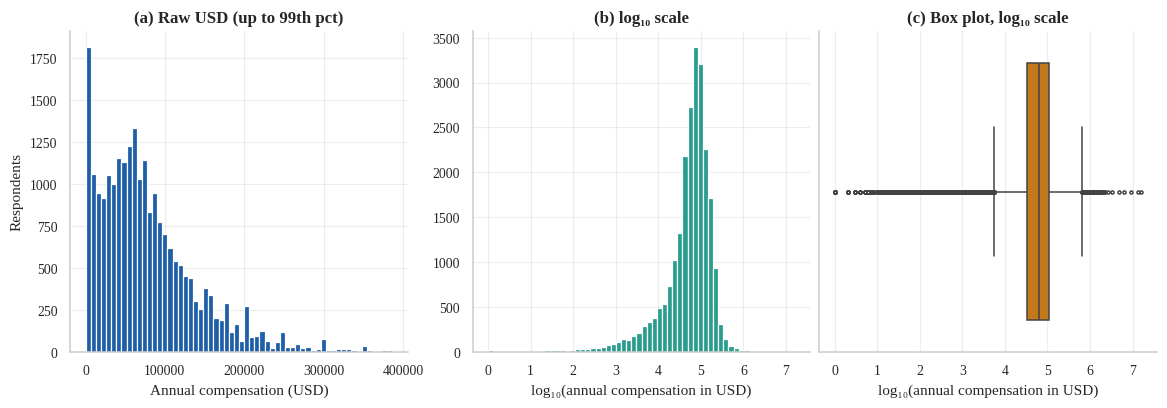

Skewness raw = 52.92 ; after log = -2.33


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.6))
axes[0].hist(comp[comp <= comp.quantile(.99)], bins=60, color=PALETTE["blue"])
axes[0].set_title("(a) Raw USD (up to 99th pct)"); axes[0].set_xlabel("Annual compensation (USD)"); axes[0].set_ylabel("Respondents")
axes[1].hist(np.log10(comp[comp > 0]), bins=60, color=PALETTE["green"])
axes[1].set_title("(b) log₁₀ scale"); axes[1].set_xlabel("log₁₀(annual compensation in USD)")
sns.boxplot(x=np.log10(comp[comp > 0]), ax=axes[2], color=PALETTE["orange"], fliersize=2)
axes[2].set_title("(c) Box plot, log₁₀ scale"); axes[2].set_xlabel("log₁₀(annual compensation in USD)")
savefig(fig, "fig02_comp_distribution", "Distribution of annual compensation: heavily right-skewed in USD (a), far less skewed after a log transform (b), with extreme tails visible in (c).", "EDA")
plt.show()
print(f"Skewness raw = {R['comp_stats_raw']['skew']:.2f} ; after log = {R['comp_stats_raw']['skew_log']:.2f}")

**Cleaning policy for the salary cohort** (documented design decision):
1. keep **professional developers** (`main_branch = 1`) with an observed converted salary and a known country;
2. absolute plausibility bounds **USD 1 000 – 1 000 000** (below = probably monthly/ typo entries; above = unverifiable);
3. **within-country 3 × IQR fences on log(salary)** for countries with ≥ 50 salaries (a *country-aware* rule — a global
   fence would wrongly delete every salary from low-income countries);
4. logically impossible experience values are **blanked, not dropped** (the row's other information is valid);
5. exact duplicate rows inside the cohort are removed.

In [10]:
cohort, attrition = build_salary_cohort(df)
dups_in_cohort = int(cohort.drop(columns="response_id").duplicated().sum())
cohort = cohort.drop_duplicates(subset=[c for c in cohort.columns if c != "response_id"]).reset_index(drop=True)
attrition.loc[len(attrition)] = ["Exact duplicate rows removed", len(cohort), dups_in_cohort]
save_table(attrition, "tbl_cohort_attrition", "Row attrition at each cleaning step for the salary cohort", "EDA")
R["cohort"] = dict(n=len(cohort), n_countries=int(cohort.country.nunique()), attrition=attrition.to_dict("records"),
                   n_india=int((cohort.country == "India").sum()), n_usa=int((cohort.country == "USA").sum()))
cohort.to_csv(DATA_PROC / "salary_cohort_clean.csv", index=False)
attrition

,step,rows,rows_removed
0,All respondents,65437,0
1,Professional developers (main_branch = 1),50207,15230
2,Reported converted yearly compensation,21549,28658
3,Country available,21549,0
4,"Absolute plausibility bounds USD 1,000-1,000,000",21007,542
5,Within-country 3 x IQR fences on log(comp),20796,211
6,Inconsistent professional-years values blanked...,20796,0
7,Exact duplicate rows removed,20794,2


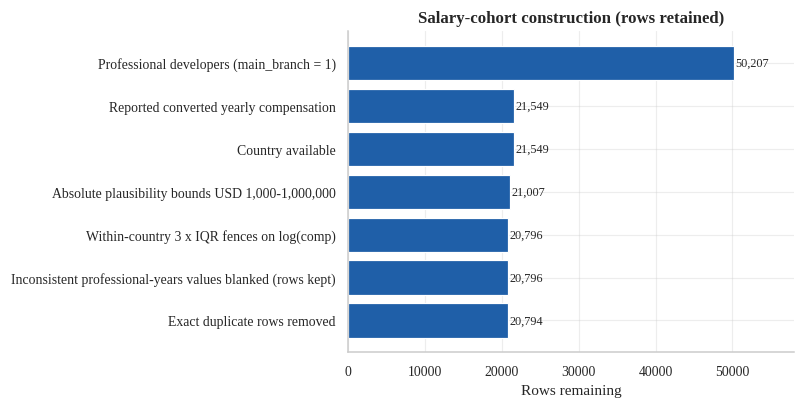

In [11]:
fig, ax = plt.subplots(figsize=(7.2, 3.6))
a = attrition.iloc[1:].reset_index(drop=True)
ax.barh(a["step"][::-1], a["rows"][::-1], color=PALETTE["blue"])
for i, v in enumerate(a["rows"][::-1]): ax.text(v + 200, i, f"{v:,}", va="center", fontsize=8)
ax.set_xlabel("Rows remaining"); ax.set_xlim(0, 58000); ax.set_title("Salary-cohort construction (rows retained)")
savefig(fig, "fig03_cohort_attrition", "Rows retained at each step of salary-cohort construction.", "EDA")
plt.show()

In [12]:
# AI cohort (all respondents with a known AI-adoption answer)
ai_cohort = build_ai_cohort(df)
ai_cohort.to_csv(DATA_PROC / "ai_cohort_clean.csv", index=False)
R["ai_cohort"] = dict(n=len(ai_cohort), adoption_rate=float(ai_cohort.uses_ai.mean() * 100),
                      dist=df.ai_select.value_counts(dropna=False).rename(str).to_dict())
print(R["ai_cohort"])
print("Skewness of log(salary) in cohort:", round(float(stats.skew(cohort.log_comp)), 3))

{'n': 60907, 'adoption_rate': 61.83525703121152, 'dist': {'Yes': 37662, "No, and I don't plan to": 14837, 'No, but I plan to soon': 8408, 'nan': 4530}}
Skewness of log(salary) in cohort: -1.142


# Part C — Exploratory data analysis (EDA)

In [13]:
desc_num = cohort[["years_code", "years_code_pro", "converted_comp_yearly", "log_comp", "age_mid", "org_mid"]].describe().T
desc_num["skew"] = cohort[desc_num.index].skew()
save_table(desc_num.reset_index().rename(columns={"index": "variable"}), "tbl_descriptives",
           "Descriptive statistics of numeric variables in the salary cohort", "EDA")
R["descriptives"] = desc_num.round(3).to_dict("index")
desc_num

,count,mean,std,min,25%,50%,75%,max,skew
years_code,"20,756.000",15.249,9.791,0.000,8.000,12.000,20.000,51.000,1.159
years_code_pro,"20,571.000",10.374,8.561,0.000,4.000,8.000,14.000,51.000,1.371
converted_comp_yearly,"20,794.000","84,886.671","76,107.461","1,000.000","37,592.000","68,733.500","110,000.000","1,000,000.000",3.222
log_comp,"20,794.000",10.946,1.044,6.908,10.535,11.138,11.608,13.816,-1.142
age_mid,"20,785.000",34.190,9.687,16.000,29.500,29.500,39.500,67.000,0.865
org_mid,"20,508.000","2,595.023","4,874.539",1.000,60.000,300.000,"3,000.000","15,000.000",1.938


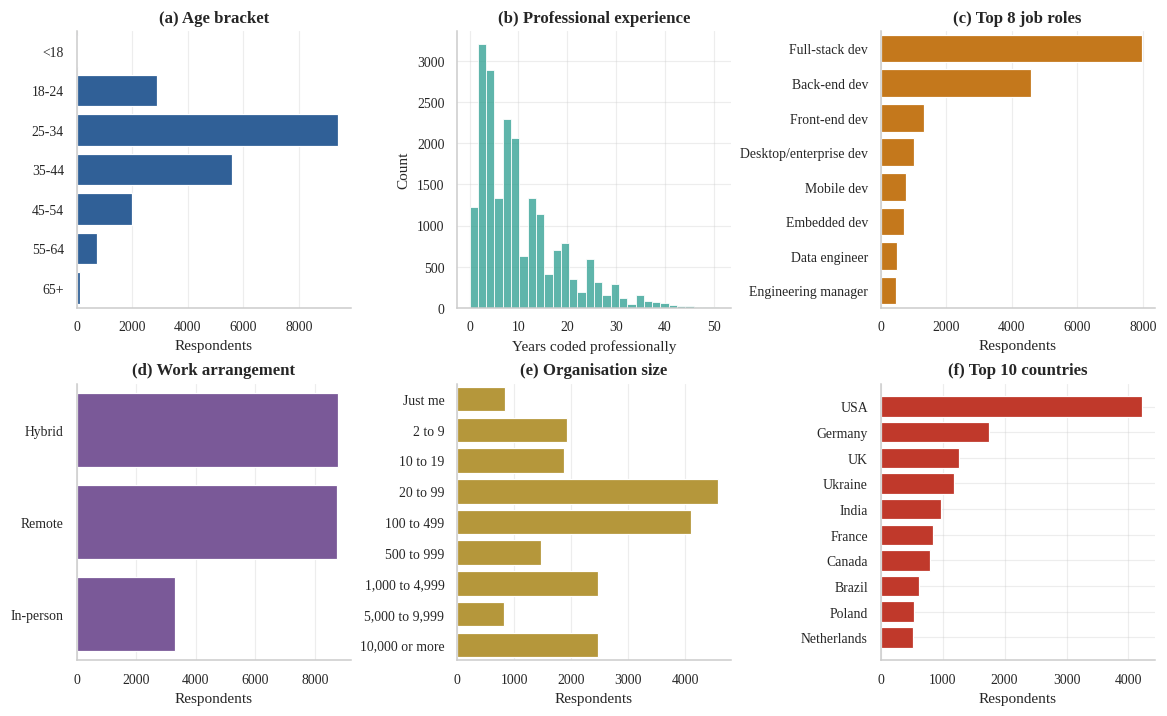

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(10.5, 6.4))
order = [a for a in AGE_ORDER if a in cohort.age.unique()]
sns.countplot(y="age", data=cohort, order=order, ax=axes[0, 0], color=PALETTE["blue"]); axes[0, 0].set_title("(a) Age bracket"); axes[0, 0].set_ylabel("")
sns.histplot(cohort["years_code_pro"].dropna(), bins=30, ax=axes[0, 1], color=PALETTE["green"]); axes[0, 1].set_title("(b) Professional experience"); axes[0, 1].set_xlabel("Years coded professionally")
top_dev = cohort.dev_type.value_counts().head(8).index
sns.countplot(y="dev_type", data=cohort[cohort.dev_type.isin(top_dev)], order=top_dev, ax=axes[0, 2], color=PALETTE["orange"]); axes[0, 2].set_title("(c) Top 8 job roles"); axes[0, 2].set_ylabel("")
sns.countplot(y="remote_work", data=cohort, ax=axes[1, 0], color=PALETTE["purple"], order=cohort.remote_work.value_counts().index); axes[1, 0].set_title("(d) Work arrangement"); axes[1, 0].set_ylabel("")
sns.countplot(y="org_short", data=cohort, order=[o for o in ORG_ORDER if o in set(cohort.org_short.dropna())], ax=axes[1, 1], color=PALETTE["gold"]); axes[1, 1].set_title("(e) Organisation size"); axes[1, 1].set_ylabel("")
topc = cohort.country.value_counts().head(10)
axes[1, 2].barh(topc.index[::-1], topc.values[::-1], color=PALETTE["red"]); axes[1, 2].set_title("(f) Top 10 countries")
for ax in axes.ravel(): ax.set_xlabel("Respondents" if ax.get_xlabel() in ("", "count") else ax.get_xlabel())
savefig(fig, "fig04_univariate_profile", f"Univariate profile of the {len(cohort):,} professional developers in the salary cohort.", "EDA")
plt.show()

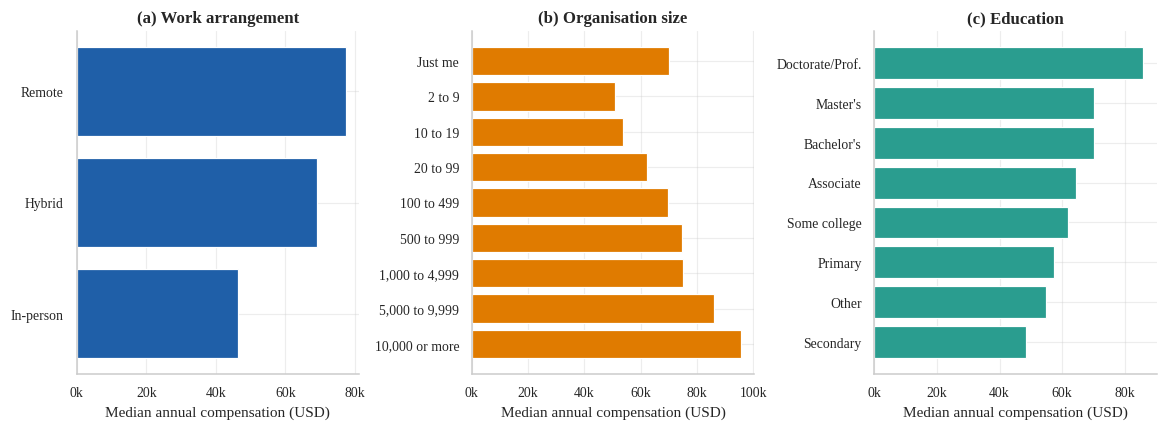

In [15]:
# Group comparison overview (EDA): median compensation (USD) by categorical groups
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.8))
g = cohort.groupby("remote_work").converted_comp_yearly.median().sort_values(); axes[0].barh(g.index, g.values, color=PALETTE["blue"]); axes[0].set_title("(a) Work arrangement")
g = cohort.groupby("org_short").converted_comp_yearly.median().reindex([o for o in ORG_ORDER if o in set(cohort.org_short.dropna())]); axes[1].barh(g.index[::-1], g.values[::-1], color=PALETTE["orange"]); axes[1].set_title("(b) Organisation size")
g = cohort.groupby("ed_short").converted_comp_yearly.median().sort_values(); axes[2].barh(g.index, g.values, color=PALETTE["green"]); axes[2].set_title("(c) Education")
for ax in axes: ax.set_xlabel("Median annual compensation (USD)"); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))
savefig(fig, "fig05_group_medians", "Raw (unadjusted) median compensation by work arrangement, organisation size and education. Country mix confounds these gaps (see O3).", "EDA")
plt.show()

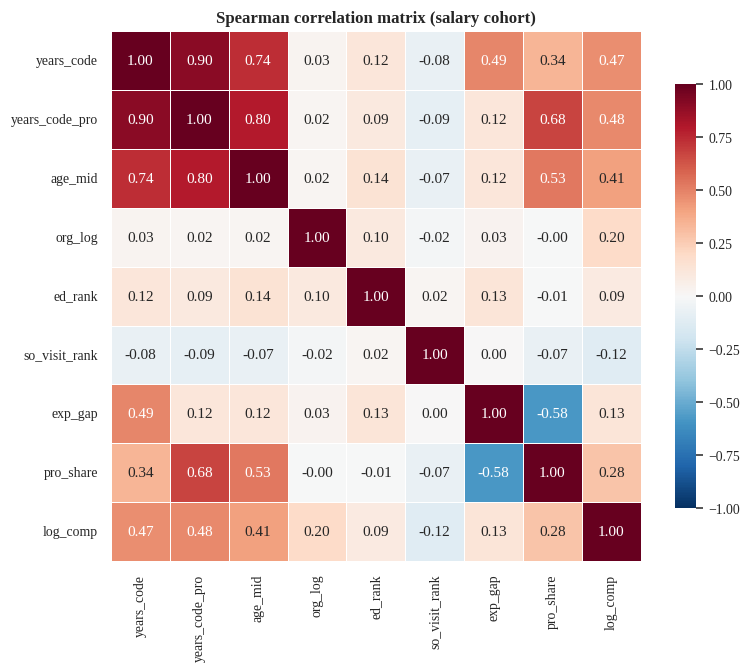

In [16]:
# Correlation structure
num_cols_eda = ["years_code", "years_code_pro", "age_mid", "org_log", "ed_rank", "so_visit_rank", "exp_gap", "pro_share", "log_comp"]
corr = cohort[num_cols_eda].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.2, 6.0))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, square=True, linewidths=.5, cbar_kws={"shrink": .8})
ax.set_title("Spearman correlation matrix (salary cohort)")
savefig(fig, "fig06_spearman_corr", "Spearman rank-correlation matrix of numeric and ordinal variables including log-compensation.", "EDA")
plt.show()
R["corr_with_logcomp"] = corr["log_comp"].drop("log_comp").round(3).to_dict()

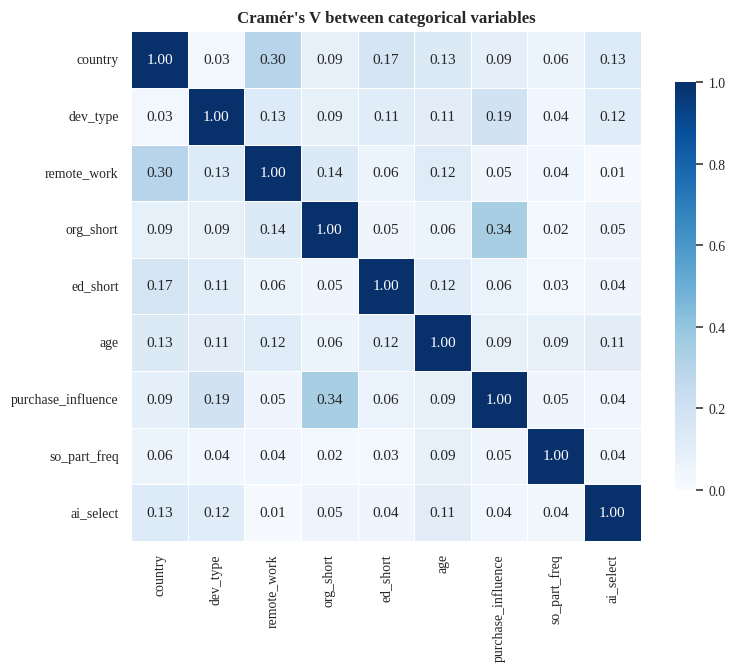

In [17]:
# Association among categorical variables (Cramér's V, bias-corrected)
cat_cols_eda = ["country", "dev_type", "remote_work", "org_short", "ed_short", "age", "purchase_influence", "so_part_freq", "ai_select"]
cv = pd.DataFrame(index=cat_cols_eda, columns=cat_cols_eda, dtype=float)
sub = cohort[cat_cols_eda].dropna()
for a in cat_cols_eda:
    for b in cat_cols_eda:
        cv.loc[a, b] = 1.0 if a == b else cramers_v(sub[a], sub[b])
fig, ax = plt.subplots(figsize=(7.2, 6.0))
sns.heatmap(cv, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax, square=True, linewidths=.5, cbar_kws={"shrink": .8})
ax.set_title("Cramér's V between categorical variables")
savefig(fig, "fig07_cramers_v", "Bias-corrected Cramér's V between categorical variables (0 = independent, 1 = perfectly associated).", "EDA")
plt.show()

In [18]:
# Multicollinearity: Variance Inflation Factors of the numeric predictors
from statsmodels.stats.outliers_influence import variance_inflation_factor
vif_cols = ["years_code", "years_code_pro", "age_mid", "org_log", "ed_rank", "so_visit_rank"]
Xv = cohort[vif_cols].dropna(); Xv = (Xv - Xv.mean()) / Xv.std(); Xv.insert(0, "const", 1.0)
vif = pd.DataFrame({"variable": vif_cols, "VIF": [variance_inflation_factor(Xv.values, i + 1) for i in range(len(vif_cols))]})
save_table(vif, "tbl_vif", "Variance inflation factors of numeric predictors", "EDA")
R["vif"] = vif.round(2).to_dict("records"); vif

,variable,VIF
0,years_code,7.072
1,years_code_pro,8.515
2,age_mid,3.567
3,org_log,1.014
4,ed_rank,1.044
5,so_visit_rank,1.006


{'dagostino_k2': 938.7207388205943, 'dagostino_p': 1.4433828508241878e-204, 'skew_logcomp': -1.1422476552575438, 'kurt_logcomp': 1.7860783204204358, 'levene_W': 385.4423447447817, 'levene_p': 0.0}


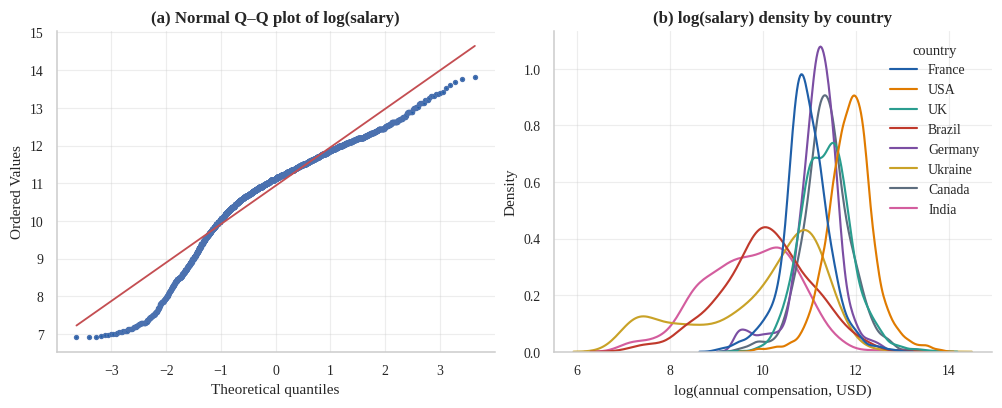

In [19]:
# Normality & homogeneity checks that justify the statistical tests chosen later
samp = cohort.log_comp.sample(5000, random_state=RANDOM_STATE)
k2 = stats.normaltest(samp)
top_c = cohort.country.value_counts().head(8).index
lev = stats.levene(*[cohort.loc[cohort.country == c, "log_comp"] for c in top_c])
R["assumptions"] = dict(dagostino_k2=float(k2.statistic), dagostino_p=float(k2.pvalue),
                        skew_logcomp=float(stats.skew(cohort.log_comp)), kurt_logcomp=float(stats.kurtosis(cohort.log_comp)),
                        levene_W=float(lev.statistic), levene_p=float(lev.pvalue))
print(R["assumptions"])
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
stats.probplot(samp, dist="norm", plot=axes[0]); axes[0].set_title("(a) Normal Q–Q plot of log(salary)")
axes[0].get_lines()[0].set_markerfacecolor(PALETTE["blue"]); axes[0].get_lines()[0].set_markersize(2.5)
sns.kdeplot(data=cohort[cohort.country.isin(top_c)], x="log_comp", hue="country", ax=axes[1], common_norm=False, palette=CAT, linewidth=1.4)
axes[1].set_title("(b) log(salary) density by country"); axes[1].set_xlabel("log(annual compensation, USD)")
savefig(fig, "fig08_normality_checks", "Q–Q plot of log-salary (a) and country-wise densities (b): log-salary is left-skewed and heavy-tailed rather than normal, with unequal location and spread across countries.", "EDA")
plt.show()

**Interpretation / decisions from EDA**
* Log-salary is roughly symmetric but heavy-tailed (excess kurtosis) and its variance differs across countries →
  we use **rank-based tests** (Kruskal–Wallis, Mann–Whitney, Spearman) and **robust (HC3) standard errors** for OLS,
  and model `log(salary)` rather than raw USD.
* `years_code`, `years_code_pro` and `age_mid` are strongly inter-correlated: VIFs of `years_code` and `years_code_pro`
  are roughly 7–9 (above the conventional 5, below 10). Tree models are immune and Ridge regularisation handles it for
  prediction; for the *inferential* OLS models (O2, O3) we deliberately use **only `years_code_pro`** so coefficients
  stay interpretable. `exp_gap` / `pro_share` are added to expose *different* information from the same columns.
* `country` and `dev_type` are high-cardinality → **cross-fitted target encoding** (tree models) or one-hot with rare
  levels pooled (Ridge).

In [20]:
# Feature-engineering register (justification table used in the report)
fe = pd.DataFrame([
 ("age_mid", "Midpoint of age bracket", "Turns an ordinal bracket into a numeric scale usable by all models"),
 ("ed_rank", "Education level -> 1…7", "Preserves natural order of qualifications"),
 ("org_log", "log10(midpoint of organisation size)", "Company size spans 4 orders of magnitude; log makes effect approx. linear"),
 ("so_visit_rank", "Stack Overflow visit frequency -> 1…5", "Proxy for engagement / learning intensity"),
 ("exp_gap", "years_code − years_code_pro", "Years of coding before first paid job (education / hobby head-start)"),
 ("pro_share", "years_code_pro / years_code", "Share of the coding life spent professionally (career stage)"),
 ("years_pro_sq", "years_code_pro²", "Captures diminishing returns of experience in linear models"),
 ("Missing indicators", "SimpleImputer(add_indicator=True)", "Non-response itself can be informative"),
 ("Target-encoded country / dev_type", "Cross-fitted mean of target by category", "Compact numeric representation of high-cardinality variables, leakage-safe"),
], columns=["feature", "definition", "justification"])
save_table(fe, "tbl_feature_engineering", "Engineered features and their justification", "EDA")
fe

,feature,definition,justification
0,age_mid,Midpoint of age bracket,Turns an ordinal bracket into a numeric scale ...
1,ed_rank,Education level -> 1…7,Preserves natural order of qualifications
2,org_log,log10(midpoint of organisation size),Company size spans 4 orders of magnitude; log ...
3,so_visit_rank,Stack Overflow visit frequency -> 1…5,Proxy for engagement / learning intensity
4,exp_gap,years_code − years_code_pro,Years of coding before first paid job (educati...
5,pro_share,years_code_pro / years_code,Share of the coding life spent professionally ...
6,years_pro_sq,years_code_pro²,Captures diminishing returns of experience in ...
7,Missing indicators,SimpleImputer(add_indicator=True),Non-response itself can be informative
8,Target-encoded country / dev_type,Cross-fitted mean of target by category,Compact numeric representation of high-cardina...


# Part D — Statistical analysis for objectives O1–O5
Reminder of the test choices justified by EDA: log-salary is heavy-tailed with unequal spread across countries,
so we use **rank-based** tests and **heteroscedasticity-robust (HC3)** regression inference.

$$H=\frac{12}{N(N+1)}\sum_{i=1}^{k}\frac{R_i^{2}}{n_i}-3(N+1),\qquad \varepsilon^{2}=\frac{H}{N-1}\quad\text{(Kruskal–Wallis and its effect size)}$$
$$\eta^{2}=\frac{SS_{between}}{SS_{total}},\qquad V=\sqrt{\frac{\tilde\chi^{2}/n}{\min(k-1,r-1)}}\quad\text{(Cramér's V)},\qquad
\hat p\pm z\sqrt{\tfrac{\hat p(1-\hat p)}{n}+\tfrac{z^{2}}{4n^{2}}}\Big/\Big(1+\tfrac{z^{2}}{n}\Big)\ \text{(Wilson)}$$

In [21]:
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.anova import anova_lm
import re

def fmt_p(p): return "< 0.001" if p < 0.001 else f"{p:.3f}"

def boot_median_ci(x, n=1000, seed=RANDOM_STATE):
    x = np.asarray(x); rng = np.random.default_rng(seed)
    meds = np.median(x[rng.integers(0, len(x), (n, len(x)))], axis=1)
    return float(np.percentile(meds, 2.5)), float(np.percentile(meds, 97.5))

cohort = pd.read_csv(DATA_PROC / "salary_cohort_clean.csv")
ai_cohort = pd.read_csv(DATA_PROC / "ai_cohort_clean.csv")
print(cohort.shape, ai_cohort.shape)

(20794, 44) (60907, 44)


## O1 — Geographic compensation inequality and India's position
**Research question.** How much of the variation in developer pay is explained by country alone, and how does India
compare with the largest developer markets? **Relevance.** Offshoring, migration decisions and salary benchmarking.
**Variables:** `country`, `converted_comp_yearly` (USD, **nominal — not purchasing-power adjusted**).
**Output & success:** η² / R² of country; India : USA median ratio with a 95 % bootstrap CI; pairwise effect sizes.

In [22]:
cc = cohort.country.value_counts()
top_c = cc[cc >= 150].index.tolist()
sub1 = cohort[cohort.country.isin(top_c)]
groups = [g.log_comp.values for _, g in sub1.groupby("country")]
H, pH = stats.kruskal(*groups); eps2 = epsilon_squared_kruskal(H, len(sub1))
eta2_top = eta_squared_from_groups(groups)
m_all = smf.ols("log_comp ~ C(country)", data=cohort).fit()
rows = []
usa_med = cohort.loc[cohort.country == "USA", "converted_comp_yearly"].median()
for c in top_c:
    x = cohort.loc[cohort.country == c, "converted_comp_yearly"].values
    lo, hi = boot_median_ci(x)
    rows.append(dict(country=c, n=len(x), median_usd=np.median(x), ci_low=lo, ci_high=hi,
                     q1=np.percentile(x, 25), q3=np.percentile(x, 75), ratio_to_usa=np.median(x) / usa_med))
ctab = pd.DataFrame(rows).sort_values("median_usd", ascending=False).reset_index(drop=True)
ctab["rank"] = np.arange(1, len(ctab) + 1)
# India vs each other top country: Mann-Whitney + Holm + Cliff's delta (positive = India higher)
ind = cohort.loc[cohort.country == "India", "log_comp"].values
pw = []
for c in top_c:
    if c == "India": continue
    o = cohort.loc[cohort.country == c, "log_comp"].values
    pw.append(dict(country=c, mwu_p=stats.mannwhitneyu(ind, o).pvalue, cliffs_delta_india_vs=cliffs_delta(ind, o)))
pw = pd.DataFrame(pw); pw["p_holm"] = multipletests(pw.mwu_p, method="holm")[1]
ctab = ctab.merge(pw, on="country", how="left")
save_table(ctab.round(3), "tbl_o1_country_stats", "Median annual compensation (USD) by country with 95 % bootstrap CI and India-vs-country effect sizes", "O1")
ind_row = ctab[ctab.country == "India"].iloc[0]
# bootstrap CI of the India:USA median ratio
rng = np.random.default_rng(RANDOM_STATE)
xi = cohort.loc[cohort.country == "India", "converted_comp_yearly"].values; xu = cohort.loc[cohort.country == "USA", "converted_comp_yearly"].values
ratios = [np.median(rng.choice(xi, len(xi))) / np.median(rng.choice(xu, len(xu))) for _ in range(2000)]
R["O1"] = dict(top_countries=top_c, n_top=len(sub1), H=float(H), p=float(pH), epsilon2=eps2, eta2_top=eta2_top,
               R2_country_all=float(m_all.rsquared), adjR2_country_all=float(m_all.rsquared_adj), n_all_countries=int(cohort.country.nunique()),
               india_median=float(ind_row.median_usd), india_n=int(ind_row.n), india_rank=int(ind_row["rank"]), n_ranked=len(ctab),
               usa_median=float(usa_med), india_usa_ratio=float(np.median(xi) / usa_med),
               india_usa_ratio_ci=[float(np.percentile(ratios, 2.5)), float(np.percentile(ratios, 97.5))],
               max_country=ctab.iloc[0][["country", "median_usd"]].to_dict(), min_country=ctab.iloc[-1][["country", "median_usd"]].to_dict(),
               india_sig_lower_than=int((ctab.country.ne("India") & (ctab.p_holm < 0.05) & (ctab.cliffs_delta_india_vs < 0)).sum()),
               india_sig_higher_than=int((ctab.country.ne("India") & (ctab.p_holm < 0.05) & (ctab.cliffs_delta_india_vs > 0)).sum()),
               top_over_bottom=float(ctab.median_usd.max() / ctab.median_usd.min()))
print(json.dumps({k: v for k, v in R["O1"].items() if k not in ("top_countries",)}, indent=1, default=str))
ctab.round(2)

{
 "n_top": 17389,
 "H": 9238.17754709689,
 "p": 0.0,
 "epsilon2": 0.5312961552275643,
 "eta2_top": 0.48641210982381855,
 "R2_country_all": 0.506973187020673,
 "adjR2_country_all": 0.5031740563012916,
 "n_all_countries": 160,
 "india_median": 17945.0,
 "india_n": 966,
 "india_rank": 28,
 "n_ranked": 28,
 "usa_median": 148000.0,
 "india_usa_ratio": 0.12125,
 "india_usa_ratio_ci": [
  0.10579965306122449,
  0.12893010793426282
 ],
 "max_country": {
  "country": "USA",
  "median_usd": 148000.0
 },
 "min_country": {
  "country": "India",
  "median_usd": 17945.0
 },
 "india_sig_lower_than": 27,
 "india_sig_higher_than": 0,
 "top_over_bottom": 8.24742268041237
}


,country,n,median_usd,ci_low,ci_high,q1,q3,ratio_to_usa,rank,mwu_p,cliffs_delta_india_vs,p_holm
0,USA,4211,"148,000.000","145,000.000","150,000.000","107,000.000","195,000.000",1.000,1,0.000,-0.960,0.000
1,Israel,198,"120,754.500","113,334.000","129,524.000","97,143.000","145,715.000",0.820,2,0.000,-0.940,0.000
2,Switzerland,334,"116,988.000","111,417.000","122,559.000","97,211.500","144,842.000",0.790,3,0.000,-0.950,0.000
3,Australia,449,"95,796.000","91,832.000","99,099.000","72,673.000","118,919.000",0.650,4,0.000,-0.910,0.000
4,Denmark,180,"91,378.000","86,401.000","100,801.000","75,774.750","115,778.000",0.620,5,0.000,-0.920,0.000
5,Canada,799,"87,231.000","83,597.000","87,231.000","65,424.000","116,309.000",0.590,6,0.000,-0.880,0.000
6,UK,1270,"85,350.000","82,802.000","89,172.000","59,872.000","121,018.000",0.580,7,0.000,-0.880,0.000
7,Norway,207,"81,424.000","76,745.000","84,232.000","68,088.000","100,610.500",0.550,8,0.000,-0.900,0.000
8,Germany,1754,"75,184.000","73,036.000","75,184.000","56,925.000","92,611.250",0.510,9,0.000,-0.830,0.000
9,Netherlands,529,"69,814.000","66,592.000","75,184.000","53,703.000","97,954.000",0.470,10,0.000,-0.830,0.000


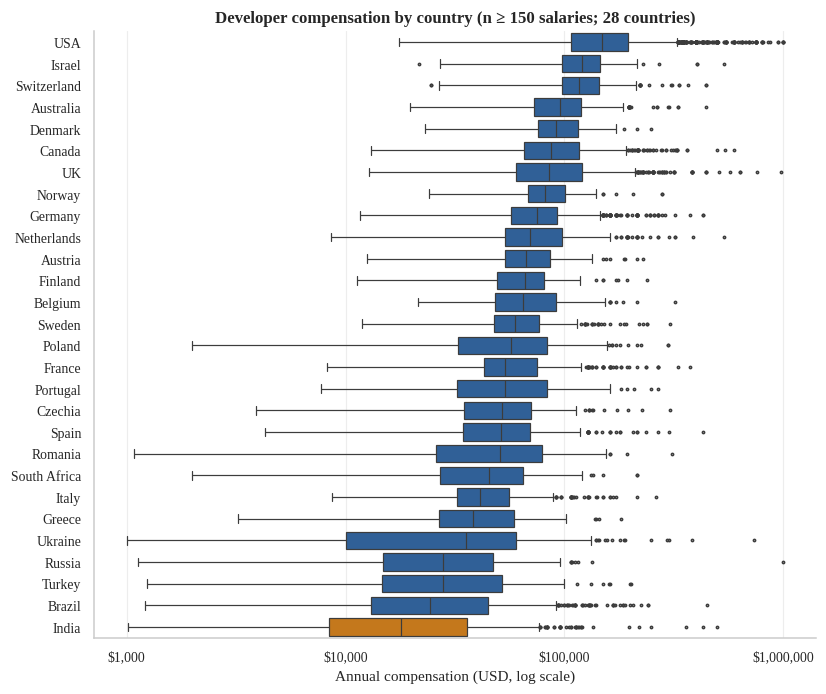

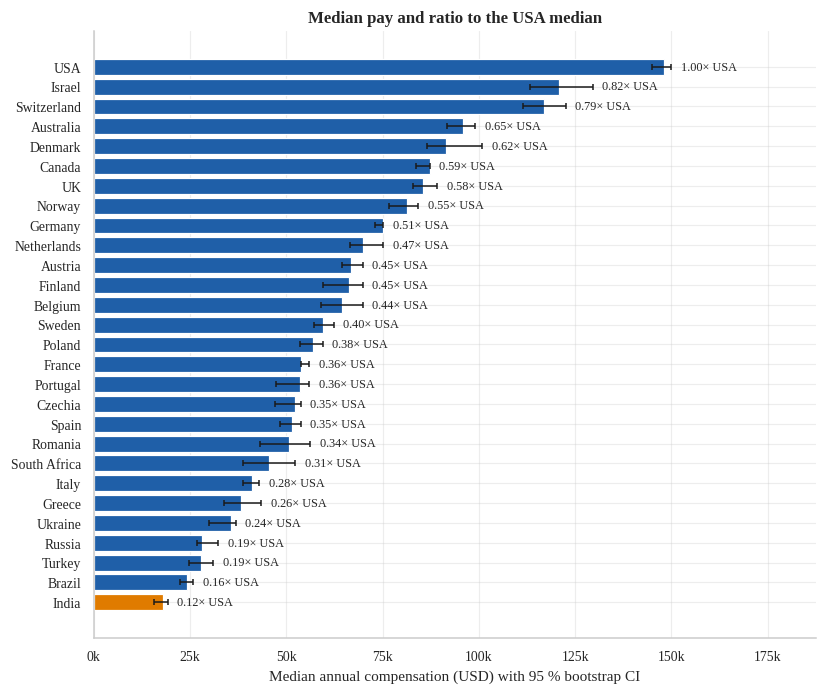

In [23]:
fig, ax = plt.subplots(figsize=(7.4, 6.2))
ordc = ctab.country.tolist()
sns.boxplot(data=sub1, y="country", x="converted_comp_yearly", order=ordc, ax=ax, fliersize=1.5, linewidth=.8,
            palette={c: (PALETTE["orange"] if c == "India" else PALETTE["blue"]) for c in ordc}, hue="country", legend=False)
ax.set_xscale("log"); ax.set_xlabel("Annual compensation (USD, log scale)"); ax.set_ylabel("")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x:,.0f}"))
ax.set_title(f"Developer compensation by country (n ≥ 150 salaries; {len(top_c)} countries)")
savefig(fig, "fig09_country_boxplot", "Distribution of annual compensation (USD, log axis) by country, ordered by median. India is highlighted in orange.", "O1")
plt.show()

fig, ax = plt.subplots(figsize=(7.4, 6.2))
d_ = ctab.iloc[::-1]
cols = [PALETTE["orange"] if c == "India" else PALETTE["blue"] for c in d_.country]
ax.barh(d_.country, d_.median_usd, color=cols, xerr=[d_.median_usd - d_.ci_low, d_.ci_high - d_.median_usd], error_kw=dict(lw=1, capsize=2))
for i, (v, r_) in enumerate(zip(d_.median_usd, d_.ratio_to_usa)): ax.text(d_.ci_high.iloc[i] + 2500, i, f"{r_:.2f}× USA", va="center", fontsize=8)
ax.set_xlabel("Median annual compensation (USD) with 95 % bootstrap CI"); ax.set_xlim(0, ctab.ci_high.max() * 1.25)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:.0f}k")); ax.set_title("Median pay and ratio to the USA median")
savefig(fig, "fig10_country_median_ci", "Median annual compensation with 95 % bootstrap confidence intervals; labels give the ratio to the USA median.", "O1")
plt.show()

## O2 — Experience premium and diminishing returns
**Research question.** How strongly does professional experience raise pay, and when do the returns flatten?
**Variables:** `years_code_pro`, `log_comp`, `country`. **Methods:** Spearman ρ (overall and within large countries);
log-linear quadratic OLS with country fixed effects and HC3 errors; delta-method CIs for the marginal effect.
$$\ln(\text{Pay}_i)=\beta_0+\beta_1 x_i+\beta_2 x_i^{2}+\gamma_{country(i)}+\varepsilon_i,\qquad
\frac{\partial \ln \text{Pay}}{\partial x}=\beta_1+2\beta_2 x \;\Rightarrow\; \%\Delta\text{Pay per extra year}\approx 100\,(e^{\beta_1+2\beta_2 x}-1),\qquad x^{*}=-\frac{\beta_1}{2\beta_2}$$
**Success:** ρ with 95 % CI; % gain per year at 0/5/10/20 years; test of India-vs-USA difference in slope.

In [24]:
e = cohort.dropna(subset=["years_code_pro"]).copy()
e["is_india"] = (e.country == "India").astype(int)
sp_all = spearman(e.years_code_pro, e.log_comp)
sp_c = {c: spearman(e.loc[e.country == c, "years_code_pro"], e.loc[e.country == c, "log_comp"]) for c in ["USA", "India", "Germany", "UK", "Ukraine", "France", "Canada"]}
m2 = smf.ols("log_comp ~ years_code_pro + years_pro_sq + C(country)", data=e).fit(cov_type="HC3")
b1, b2 = m2.params["years_code_pro"], m2.params["years_pro_sq"]
names = ["years_code_pro", "years_pro_sq"]; V2 = m2.cov_params().loc[names, names].values
def marg(x, b1=b1, b2=b2, V=V2):
    g = np.array([1, 2 * x]); me = g @ np.array([b1, b2]); se = np.sqrt(g @ V @ g)
    return [100 * (np.exp(v) - 1) for v in (me, me - 1.96 * se, me + 1.96 * se)]
me_tab = pd.DataFrame([dict(years=x, pct_per_year=marg(x)[0], ci_low=marg(x)[1], ci_high=marg(x)[2]) for x in [0, 2, 5, 10, 15, 20, 30]])
peak = -b1 / (2 * b2) if b2 < 0 else np.nan
# India-vs-USA slope difference
iu = e[e.country.isin(["India", "USA"])]
m_int = smf.ols("log_comp ~ years_code_pro + years_pro_sq + is_india + years_code_pro:is_india + years_pro_sq:is_india", data=iu).fit(cov_type="HC3")
# separate fits
sep = {}
for c in ["USA", "India", "Germany", "UK"]:
    mc = smf.ols("log_comp ~ years_code_pro + years_pro_sq", data=e[e.country == c]).fit(cov_type="HC3")
    sep[c] = dict(b1=float(mc.params["years_code_pro"]), b2=float(mc.params["years_pro_sq"]), V=mc.cov_params().values.tolist()[1:], r2=float(mc.rsquared),
                  pct_at_5=float(100 * (np.exp(mc.params["years_code_pro"] + 10 * mc.params["years_pro_sq"]) - 1)),
                  pct_at_0=float(100 * (np.exp(mc.params["years_code_pro"]) - 1)))
# bootstrap CI of Spearman (overall) as a robustness check
bl = bootstrap_ci(lambda d: stats.spearmanr(d.years_code_pro, d.log_comp)[0], e[["years_code_pro", "log_comp"]], n_boot=300)
R["O2"] = dict(n=len(e), spearman_all=sp_all, spearman_by_country=sp_c, spearman_boot_ci=list(bl),
               beta1=float(b1), beta2=float(b2), peak_years=float(peak), r2_quad=float(m2.rsquared),
               p_beta1=float(m2.pvalues["years_code_pro"]), p_beta2=float(m2.pvalues["years_pro_sq"]), marginal=me_tab.round(2).to_dict("records"),
               interaction_linear=dict(coef=float(m_int.params["years_code_pro:is_india"]), p=float(m_int.pvalues["years_code_pro:is_india"]),
                                       coef_sq=float(m_int.params["years_pro_sq:is_india"]), p_sq=float(m_int.pvalues["years_pro_sq:is_india"])),
               separate_fits={k: {kk: vv for kk, vv in v.items() if kk != "V"} for k, v in sep.items()})
save_table(me_tab.round(2), "tbl_o2_marginal", "Estimated % change in pay per additional year of professional experience (country fixed effects)", "O2")
print(json.dumps({k: v for k, v in R["O2"].items() if k != "marginal"}, indent=1, default=str)); me_tab.round(2)

{
 "n": 20571,
 "spearman_all": {
  "rho": 0.47665292907853113,
  "p": 0.0,
  "n": 20571,
  "ci_low": 0.4653806228241997,
  "ci_high": 0.48777064147067645
 },
 "spearman_by_country": {
  "USA": {
   "rho": 0.44065841234072306,
   "p": 3.3995320430579576e-198,
   "n": 4181,
   "ci_low": 0.4143945003298226,
   "ci_high": 0.4661889703722219
  },
  "India": {
   "rho": 0.6172148426688939,
   "p": 4.2601953101330643e-100,
   "n": 943,
   "ci_low": 0.5735046308325761,
   "ci_high": 0.6574206424488002
  },
  "Germany": {
   "rho": 0.5469097674076618,
   "p": 4.413946301600169e-136,
   "n": 1737,
   "ci_low": 0.5109901233302596,
   "ci_high": 0.5809227535701782
  },
  "UK": {
   "rho": 0.44782297893978346,
   "p": 8.852001590016384e-63,
   "n": 1252,
   "ci_low": 0.3996118167620002,
   "ci_high": 0.4935635992060807
  },
  "Ukraine": {
   "rho": 0.35229747457180216,
   "p": 2.7532715855032985e-35,
   "n": 1162,
   "ci_low": 0.29773971570334756,
   "ci_high": 0.40456145886340195
  },
  "France":

,years,pct_per_year,ci_low,ci_high
0,0,9.240,8.850,9.630
1,2,8.430,8.090,8.770
2,5,7.230,6.960,7.500
3,10,5.260,5.090,5.430
4,15,3.320,3.210,3.430
5,20,1.420,1.270,1.570
6,30,-2.280,-2.610,-1.950


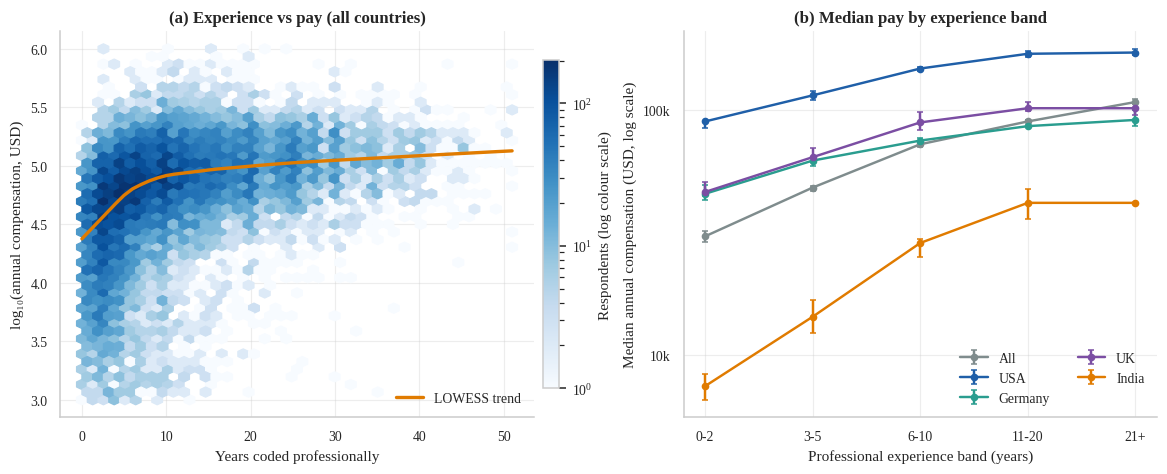

In [25]:
bands = ["0-2", "3-5", "6-10", "11-20", "21+"]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
hb = axes[0].hexbin(e.years_code_pro, np.log10(e.converted_comp_yearly), gridsize=40, cmap="Blues", mincnt=1, bins="log")
import statsmodels.nonparametric.smoothers_lowess as lw
lo_ = lw.lowess(np.log10(e.converted_comp_yearly), e.years_code_pro, frac=0.3, return_sorted=True)
axes[0].plot(lo_[:, 0], lo_[:, 1], color=PALETTE["orange"], lw=2.2, label="LOWESS trend")
axes[0].set_xlabel("Years coded professionally"); axes[0].set_ylabel("log₁₀(annual compensation, USD)"); axes[0].legend(loc="lower right")
axes[0].set_title("(a) Experience vs pay (all countries)"); fig.colorbar(hb, ax=axes[0], label="Respondents (log colour scale)", shrink=.85, pad=0.02)
for c, col in zip(["All", "USA", "Germany", "UK", "India"], [PALETTE["grey"], PALETTE["blue"], PALETTE["green"], PALETTE["purple"], PALETTE["orange"]]):
    dd = e if c == "All" else e[e.country == c]
    g = dd.groupby("exp_band").converted_comp_yearly
    med = g.median().reindex(bands); n_ = g.size().reindex(bands)
    ci = [boot_median_ci(dd.loc[dd.exp_band == b, "converted_comp_yearly"].values, n=300) if n_[b] >= 20 else (np.nan, np.nan) for b in bands]
    axes[1].errorbar(range(len(bands)), med, yerr=[med - [x[0] for x in ci], [x[1] for x in ci] - med], marker="o", ms=4, capsize=2, label=c, color=col, lw=1.6)
axes[1].set_xticks(range(len(bands))); axes[1].set_xticklabels(bands); axes[1].set_yscale("log"); axes[1].set_xlabel("Professional experience band (years)")
axes[1].set_ylabel("Median annual compensation (USD, log scale)"); axes[1].set_title("(b) Median pay by experience band"); axes[1].legend(ncol=2)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))
savefig(fig, "fig11_experience_vs_pay", "Relationship between professional experience and pay: hexbin density with LOWESS trend (a) and median pay by experience band for selected countries with 95 % bootstrap CIs (b).", "O2")
plt.show()

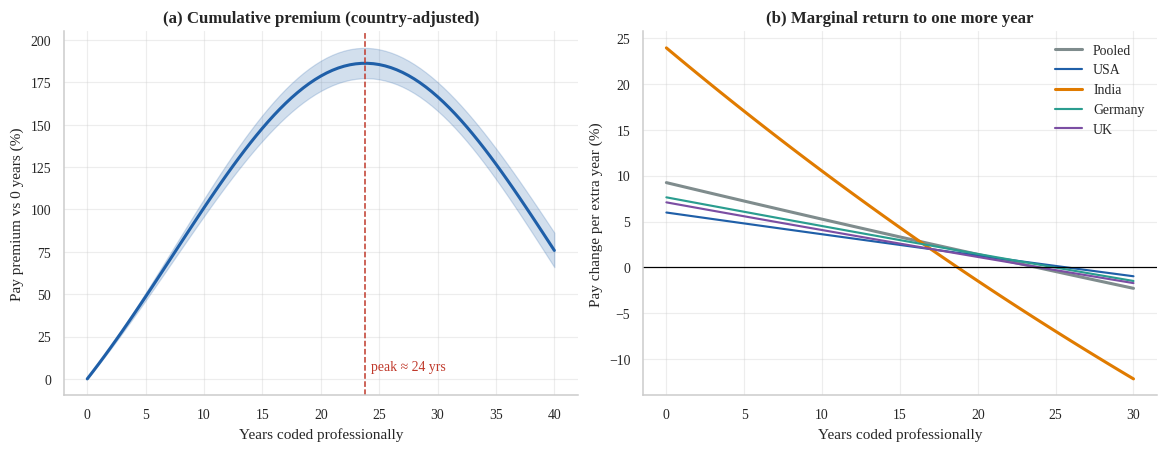

In [26]:
xs = np.linspace(0, 40, 81)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.0))
prem = 100 * (np.exp(b1 * xs + b2 * xs ** 2) - 1)
Vf = [(np.array([x, x * x]) @ V2 @ np.array([x, x * x])) ** .5 for x in xs]
lo_c = 100 * (np.exp(b1 * xs + b2 * xs ** 2 - 1.96 * np.array(Vf)) - 1); hi_c = 100 * (np.exp(b1 * xs + b2 * xs ** 2 + 1.96 * np.array(Vf)) - 1)
axes[0].plot(xs, prem, color=PALETTE["blue"], lw=2); axes[0].fill_between(xs, lo_c, hi_c, color=PALETTE["blue"], alpha=.2)
if not np.isnan(peak): axes[0].axvline(peak, color=PALETTE["red"], ls="--", lw=1); axes[0].text(peak + .5, prem.min() + 5, f"peak ≈ {peak:.0f} yrs", color=PALETTE["red"], fontsize=9)
axes[0].set_xlabel("Years coded professionally"); axes[0].set_ylabel("Pay premium vs 0 years (%)"); axes[0].set_title("(a) Cumulative premium (country-adjusted)")
xs2 = np.linspace(0, 30, 61)      # display range limited to where every country has data
for c, col in [("Pooled", PALETTE["grey"]), ("USA", PALETTE["blue"]), ("India", PALETTE["orange"]), ("Germany", PALETTE["green"]), ("UK", PALETTE["purple"])]:
    if c == "Pooled": bb1, bb2 = b1, b2
    else: bb1, bb2 = sep[c]["b1"], sep[c]["b2"]
    axes[1].plot(xs2, 100 * (np.exp(bb1 + 2 * bb2 * xs2) - 1), label=c, color=col, lw=2 if c in ("Pooled", "India") else 1.4)
axes[1].axhline(0, color="black", lw=.8); axes[1].set_xlabel("Years coded professionally"); axes[1].set_ylabel("Pay change per extra year (%)")
axes[1].set_title("(b) Marginal return to one more year"); axes[1].legend()
savefig(fig, "fig12_experience_marginal", "Quadratic log-linear model: cumulative premium with 95 % CI (a) and marginal percentage return per additional year, pooled and by country (b).", "O2")
plt.show()

## O3 — Net effects of role, work mode, organisation size and education
**Research question.** After holding country and experience constant, how much more or less do different roles,
work arrangements, company sizes and education levels earn? **Method:** OLS on log-pay with HC3 errors; adjusted
effect = $100(e^{\beta}-1)\%$ relative to a reference category; block importance by nested-model $\Delta R^{2}$ and
partial $\eta^2_p=SS_{effect}/(SS_{effect}+SS_{resid})$. **Reference categories** (largest/most typical): Full-stack
dev, In-person, 100 to 499 employees, Bachelor's.

In [27]:
o3 = cohort.dropna(subset=["years_code_pro", "dev_type", "remote_work", "org_short", "ed_short"]).copy()
o3 = o3[o3.org_short != "Don't know"]; o3 = o3[o3.ed_short != "Other"]
role_n = o3.dev_type.value_counts(); o3["dev_g"] = np.where(o3.dev_type.map(role_n) >= 100, o3.dev_type, "Other (rare roles)")
cn = o3.country.value_counts(); o3["country_g"] = np.where(o3.country.map(cn) >= 100, o3.country, "Other (small countries)")
REF = dict(dev='Full-stack dev', rem='In-person', org='100 to 499', ed="Bachelor's")
f_c = "C(country_g)"; f_x = "years_code_pro + years_pro_sq"
f_d = f'C(dev_g, Treatment(reference="{REF["dev"]}"))'; f_r = f'C(remote_work, Treatment(reference="{REF["rem"]}"))'
f_o = f'C(org_short, Treatment(reference="{REF["org"]}"))'; f_e = f'C(ed_short, Treatment(reference="{REF["ed"]}"))'
blocks = [("M0: country only", f_c), ("M1: + experience", f"{f_c} + {f_x}"), ("M2: + job role", f"{f_c} + {f_x} + {f_d}"),
          ("M3: + organisation size", f"{f_c} + {f_x} + {f_d} + {f_o}"), ("M4: + work arrangement", f"{f_c} + {f_x} + {f_d} + {f_o} + {f_r}"),
          ("M5: + education", f"{f_c} + {f_x} + {f_d} + {f_o} + {f_r} + {f_e}")]
fits, nest = [], []
for name, rhs in blocks:
    mm = smf.ols(f"log_comp ~ {rhs}", data=o3).fit(); fits.append(mm)
    prev = fits[-2] if len(fits) > 1 else None
    pF = float(mm.compare_f_test(prev)[1]) if prev is not None else float(mm.f_pvalue)
    nest.append(dict(model=name, R2=mm.rsquared, adj_R2=mm.rsquared_adj, delta_R2=mm.rsquared - (prev.rsquared if prev is not None else 0), p_F_block=pF, n=int(mm.nobs)))
nest = pd.DataFrame(nest); save_table(nest.round(4), "tbl_o3_nested_models", "Nested OLS models: incremental explanatory power of each predictor block", "O3")
full = smf.ols(f"log_comp ~ {blocks[-1][1]}", data=o3).fit(cov_type="HC3")
aov = anova_lm(smf.ols(f"log_comp ~ {blocks[-1][1]}", data=o3).fit(), typ=2)
ss_res = aov.loc["Residual", "sum_sq"]; aov["partial_eta2"] = aov["sum_sq"] / (aov["sum_sq"] + ss_res); aov = aov.drop(index="Residual")
aov.index = [re.sub(r"C\((\w+)(,.*)?\)", r"\1", i) for i in aov.index]
coef = pd.DataFrame({"coef": full.params, "se": full.bse, "p": full.pvalues, "lo": full.conf_int()[0], "hi": full.conf_int()[1]})
coef["pct"] = 100 * (np.exp(coef.coef) - 1); coef["pct_lo"] = 100 * (np.exp(coef.lo) - 1); coef["pct_hi"] = 100 * (np.exp(coef.hi) - 1)
coef["term"] = coef.index.map(lambda s: re.sub(r".*\[T\.(.*)\]", r"\1", s)); coef["var"] = coef.index.map(lambda s: re.sub(r"C\((\w+)[,)].*", r"\1", s) if s.startswith("C(") else s)
eff = coef[coef.index.str.startswith("C(") & ~coef["var"].isin(["country_g"])].copy()
save_table(eff[["var", "term", "pct", "pct_lo", "pct_hi", "p"]].round(3), "tbl_o3_adjusted_effects", "Adjusted percentage effects on annual compensation (HC3 robust 95 % CI)", "O3")
# raw vs adjusted for work arrangement
raw_remote = o3.groupby("remote_work").converted_comp_yearly.median()
R["O3"] = dict(n=int(full.nobs), nested=nest.round(4).to_dict("records"), partial_eta2=aov["partial_eta2"].round(4).to_dict(),
               final_R2=float(full.rsquared), final_adjR2=float(full.rsquared_adj), ref=REF,
               raw_remote_median=raw_remote.round(0).to_dict(), n_roles=int(o3.dev_g.nunique()),
               adj=eff[["var", "term", "pct", "pct_lo", "pct_hi", "p"]].round(3).to_dict("records"))
print(nest.round(4)); print(aov[["sum_sq", "partial_eta2"]].round(4)); eff[["var", "term", "pct", "pct_lo", "pct_hi", "p"]].round(2).sort_values("pct")

                     model    R2  adj_R2  delta_R2  p_F_block      n
0         M0: country only 0.449   0.448     0.449      0.000  20084
1         M1: + experience 0.540   0.539     0.092      0.000  20084
2           M2: + job role 0.552   0.551     0.012      0.000  20084
3  M3: + organisation size 0.563   0.561     0.010      0.000  20084
4   M4: + work arrangement 0.569   0.568     0.006      0.000  20084
5          M5: + education 0.574   0.572     0.005      0.000  20084
                  sum_sq  partial_eta2
country_g      7,126.354         0.435
dev_g            176.262         0.019
org_short        210.517         0.022
remote_work      137.270         0.015
ed_short         106.757         0.011
years_code_pro 1,045.816         0.102
years_pro_sq     555.729         0.057


,var,term,pct,pct_lo,pct_hi,p
"C(dev_g, Treatment(reference=""Full-stack dev""))[T.Academic researcher]",dev_g,Academic researcher,-28.500,-36.880,-19.010,0.000
"C(org_short, Treatment(reference=""100 to 499""))[T.2 to 9]",org_short,2 to 9,-19.320,-22.530,-15.980,0.000
"C(ed_short, Treatment(reference=""Bachelor's""))[T.Secondary]",ed_short,Secondary,-14.050,-17.820,-10.110,0.000
"C(org_short, Treatment(reference=""100 to 499""))[T.Just me]",org_short,Just me,-13.350,-18.650,-7.710,0.000
"C(org_short, Treatment(reference=""100 to 499""))[T.10 to 19]",org_short,10 to 19,-11.910,-15.360,-8.320,0.000
"C(ed_short, Treatment(reference=""Bachelor's""))[T.Associate]",ed_short,Associate,-10.260,-14.590,-5.710,0.000
"C(ed_short, Treatment(reference=""Bachelor's""))[T.Primary]",ed_short,Primary,-8.940,-22.710,7.280,0.260
"C(ed_short, Treatment(reference=""Bachelor's""))[T.Some college]",ed_short,Some college,-7.170,-9.960,-4.280,0.000
"C(org_short, Treatment(reference=""100 to 499""))[T.20 to 99]",org_short,20 to 99,-2.380,-5.120,0.440,0.100
"C(dev_g, Treatment(reference=""Full-stack dev""))[T.Desktop/enterprise dev]",dev_g,Desktop/enterprise dev,0.970,-3.370,5.500,0.670


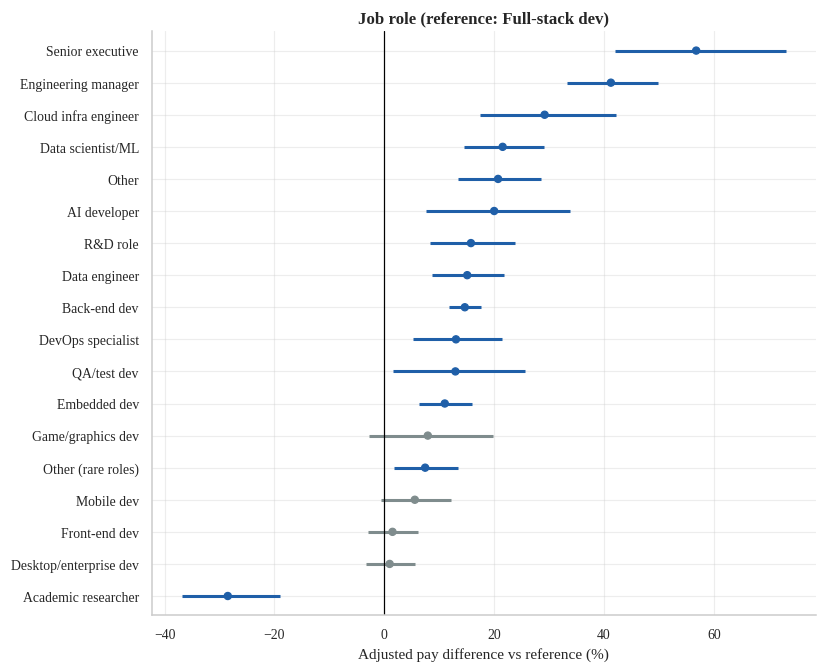

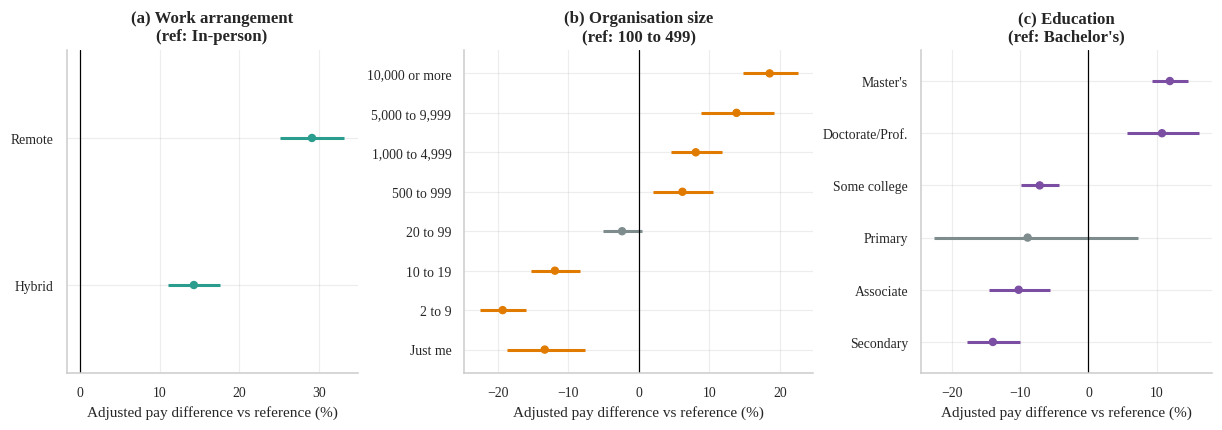

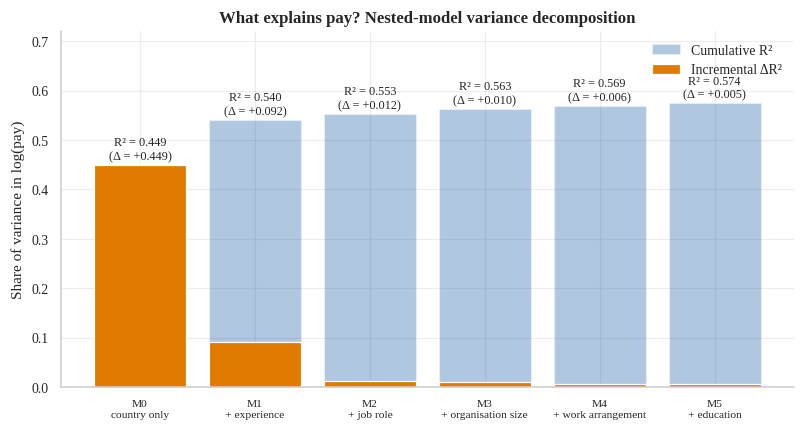

In [28]:
def forest(ax, d, title, color=PALETTE["blue"]):
    d = d.sort_values("pct"); y = np.arange(len(d))
    sig = (d.pct_lo > 0) | (d.pct_hi < 0)
    ax.hlines(y, d.pct_lo, d.pct_hi, color=np.where(sig, color, PALETTE["grey"]), lw=2)
    ax.scatter(d.pct, y, color=np.where(sig, color, PALETTE["grey"]), zorder=3, s=22)
    ax.axvline(0, color="black", lw=.8); ax.set_yticks(y); ax.set_yticklabels(d.term); ax.set_title(title); ax.set_ylim(-0.6, len(d) - 0.4)
    ax.set_xlabel("Adjusted pay difference vs reference (%)")
fig, ax = plt.subplots(figsize=(7.4, 6.0))
forest(ax, eff[eff["var"] == "dev_g"], f"Job role (reference: {REF['dev']})")
savefig(fig, "fig13_role_effects", "Adjusted pay difference by job role relative to full-stack developers (country and experience held constant; 95 % HC3 CIs; grey = not significant at 5 %).", "O3")
plt.show()
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), gridspec_kw=dict(width_ratios=[1, 1.2, 1]))
forest(axes[0], eff[eff["var"] == "remote_work"], f"(a) Work arrangement\n(ref: {REF['rem']})", PALETTE["green"])
d_o = eff[eff["var"] == "org_short"].copy(); d_o["o"] = d_o.term.map({k: i for i, k in enumerate(ORG_ORDER)}); d_o = d_o.sort_values("o")
y = np.arange(len(d_o)); sig = (d_o.pct_lo > 0) | (d_o.pct_hi < 0)
axes[1].hlines(y, d_o.pct_lo, d_o.pct_hi, color=np.where(sig, PALETTE["orange"], PALETTE["grey"]), lw=2); axes[1].scatter(d_o.pct, y, color=np.where(sig, PALETTE["orange"], PALETTE["grey"]), zorder=3, s=22)
axes[1].axvline(0, color="black", lw=.8); axes[1].set_ylim(-0.6, len(d_o) - 0.4); axes[1].set_yticks(y); axes[1].set_yticklabels(d_o.term); axes[1].set_title(f"(b) Organisation size\n(ref: {REF['org']})"); axes[1].set_xlabel("Adjusted pay difference vs reference (%)")
forest(axes[2], eff[eff["var"] == "ed_short"], f"(c) Education\n(ref: {REF['ed']})", PALETTE["purple"])
savefig(fig, "fig14_workmode_org_edu_effects", "Adjusted pay differences by work arrangement (a), organisation size (b) and education (c).", "O3")
plt.show()
fig, ax = plt.subplots(figsize=(7.2, 3.8))
ax.bar(nest.model.str.replace(": ", "\n", regex=False), nest.R2, color=PALETTE["blue"], alpha=.35, label="Cumulative R²")
ax.bar(nest.model.str.replace(": ", "\n", regex=False), nest.delta_R2, color=PALETTE["orange"], label="Incremental ΔR²")
for i, (r_, d_) in enumerate(zip(nest.R2, nest.delta_R2)): ax.text(i, r_ + .012, f"R² = {r_:.3f}\n(Δ = +{d_:.3f})", ha="center", fontsize=8)
ax.set_ylabel("Share of variance in log(pay)"); ax.set_ylim(0, .72); ax.legend(loc="upper right"); ax.set_title("What explains pay? Nested-model variance decomposition")
plt.setp(ax.get_xticklabels(), fontsize=7.5)
savefig(fig, "fig15_variance_decomposition", "Cumulative R² and incremental ΔR² as predictor blocks are added to the OLS model for log-compensation.", "O3")
plt.show()
save_results()

## O4 — Who uses AI tools? The adoption landscape
**Research question.** Which developer groups (age, experience, role, country, company size, Stack Overflow
engagement) have adopted AI tools, and is India different from the rest of the world?
**Variables:** `uses_ai` (1 = currently uses AI tools; 0 = does not), plus group factors. **Methods:** χ² test of
independence, bias-corrected Cramér's V (effect size), Wilson 95 % CIs, two-proportion z-test.
**Success:** adoption % with CI per group; ranking of factors by V; India-vs-world gap with p-value.

In [29]:
ai = ai_cohort.copy()
ai["exp_band"] = pd.Categorical(ai.exp_band, categories=bands, ordered=True)
ai = ai[ai.age != "Prefer not to say"].copy() if False else ai       # keep all rows; filter inside each factor
overall = ai.uses_ai.mean() * 100
FACTORS = {"age": "Age bracket", "exp_band": "Professional experience", "main_branch": "Coding relationship", "dev_type": "Job role",
           "country": "Country", "org_short": "Organisation size", "remote_work": "Work arrangement", "so_visit_freq": "Stack Overflow visits",
           "ed_short": "Education", "purchase_influence": "Purchasing influence"}
rows = []
for f, label in FACTORS.items():
    t = ai[[f, "uses_ai"]].dropna()
    if f == "age": t = t[t.age != "Prefer not to say"]
    if f in ("dev_type", "country"):                       # keep only groups with >= 300 respondents for stable estimates
        t = t[t[f].map(t[f].value_counts()) >= 300]
    r_ = chi2_test(t[f].astype(str), t["uses_ai"].astype(int)); r_.update(factor=f, label=label, k=t[f].nunique())
    rows.append(r_)
ftab = pd.DataFrame(rows).sort_values("cramers_v", ascending=False)
save_table(ftab[["label", "k", "n", "chi2", "dof", "p", "cramers_v"]].round(4), "tbl_o4_factor_tests", "Chi-square tests of AI adoption against each factor, ranked by Cramér's V", "O4")
def rate_table(f, min_n=300, drop=()):
    t = ai[[f, "uses_ai"]].dropna(); t = t[~t[f].isin(drop)]
    g = t.groupby(f, observed=True).uses_ai.agg(["sum", "count"]); g = g[g["count"] >= min_n]
    g["rate"] = g["sum"] / g["count"] * 100
    lo, hi = wilson_ci(g["sum"], g["count"]); g["lo"], g["hi"] = lo * 100, hi * 100
    return g.reset_index()
# India vs rest and India vs USA
ind_ai = ai[ai.country == "India"].uses_ai; rest_ai = ai[ai.country != "India"].uses_ai; usa_ai = ai[ai.country == "USA"].uses_ai
z_rest = two_prop_ztest(ind_ai.sum(), len(ind_ai), rest_ai.sum(), len(rest_ai)); z_usa = two_prop_ztest(ind_ai.sum(), len(ind_ai), usa_ai.sum(), len(usa_ai))
rt = {f: rate_table(f, drop=("Prefer not to say",)) for f in FACTORS}
R["O4"] = dict(n=len(ai), overall_rate=float(overall), factors=ftab[["factor", "label", "k", "n", "chi2", "dof", "p", "cramers_v"]].round(4).to_dict("records"),
               india=dict(n=int(len(ind_ai)), rate=float(ind_ai.mean() * 100), vs_rest=z_rest, vs_usa=z_usa, usa_rate=float(usa_ai.mean() * 100), rest_rate=float(rest_ai.mean() * 100)),
               by_age=rt["age"].round(2).to_dict("records"), by_exp=rt["exp_band"].round(2).to_dict("records"), by_branch=rt["main_branch"].round(2).to_dict("records"),
               by_so=rt["so_visit_freq"].round(2).to_dict("records"), by_org=rt["org_short"].round(2).to_dict("records"), by_remote=rt["remote_work"].round(2).to_dict("records"),
               by_role=rt["dev_type"].sort_values("rate", ascending=False).round(2).to_dict("records"), by_country=rt["country"].sort_values("rate", ascending=False).round(2).to_dict("records"),
               plan_share=float((ai_cohort.ai_select == "No, but I plan to soon").mean() * 100), never_share=float((ai_cohort.ai_select == "No, and I don't plan to").mean() * 100))
print(f"overall adoption = {overall:.1f}%  | India = {ind_ai.mean()*100:.1f}% (n={len(ind_ai)}) vs rest {rest_ai.mean()*100:.1f}% ; z-test p = {fmt_p(z_rest['p'])}")
ftab[["label", "k", "n", "chi2", "p", "cramers_v"]].round(4)

overall adoption = 61.8%  | India = 67.9% (n=4161) vs rest 61.4% ; z-test p = < 0.001


,label,k,n,chi2,p,cramers_v
0,Age bracket,7,60630,"1,574.114",0.000,0.161
1,Professional experience,5,49722,"1,220.607",0.000,0.156
3,Job role,26,56641,"1,257.402",0.000,0.147
4,Country,39,51116,"1,014.581",0.000,0.138
2,Coding relationship,5,60907,433.940,0.000,0.084
5,Organisation size,10,46343,288.254,0.000,0.078
9,Purchasing influence,3,46301,157.592,0.000,0.058
8,Education,8,58896,184.399,0.000,0.055
6,Work arrangement,3,51100,38.642,0.000,0.027
7,Stack Overflow visits,5,58286,29.916,0.000,0.021


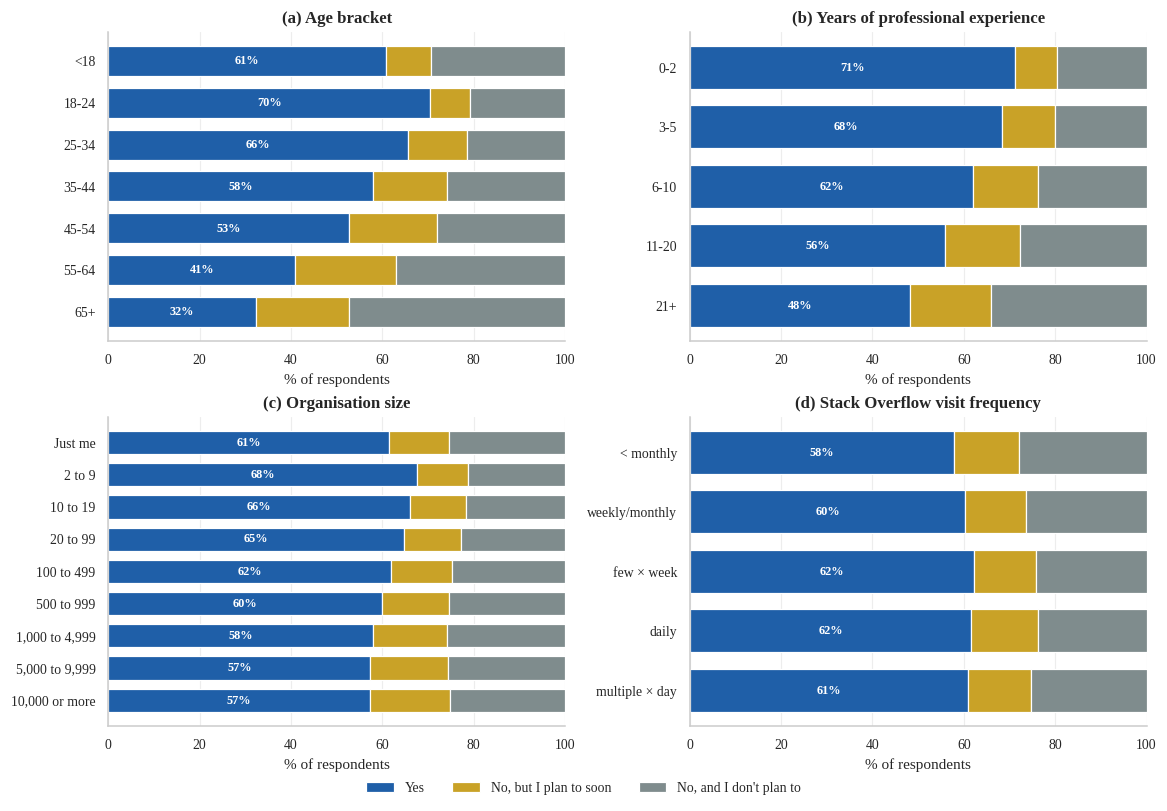

In [30]:
# Figure: 100 % stacked bars of the full 3-level answer by age, experience, organisation size and Stack Overflow frequency
LV = ["Yes", "No, but I plan to soon", "No, and I don't plan to"]; LVC = [PALETTE["blue"], PALETTE["gold"], PALETTE["grey"]]
fig, axes = plt.subplots(2, 2, figsize=(10.5, 7.0))
def stacked(ax, f, order, title, drop=()):
    t = ai[ai[f].notna() & ~ai[f].isin(drop)]; ct = pd.crosstab(t[f], t.ai_select, normalize="index").reindex(order)[LV] * 100
    left = np.zeros(len(ct))
    for lv, c in zip(LV, LVC):
        ax.barh(range(len(ct)), ct[lv], left=left, color=c, label=lv if lv not in ax.get_legend_handles_labels()[1] else None, height=.72)
        if lv == "Yes":
            for i, v in enumerate(ct[lv]): ax.text(v / 2, i, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=8, fontweight="bold")
        left += ct[lv].values
    ax.set_yticks(range(len(ct))); ax.set_yticklabels([f"{o}" for o in ct.index]); ax.set_xlim(0, 100); ax.set_xlabel("% of respondents"); ax.set_title(title); ax.invert_yaxis()
stacked(axes[0, 0], "age", [a for a in AGE_ORDER if a in set(ai.age.dropna())], "(a) Age bracket", drop=("Prefer not to say",))
stacked(axes[0, 1], "exp_band", bands, "(b) Years of professional experience")
stacked(axes[1, 0], "org_short", [o for o in ORG_ORDER if o in set(ai.org_short.dropna())], "(c) Organisation size")
sov = ["Less than once per month or monthly", "A few times per month or weekly", "A few times per week", "Daily or almost daily", "Multiple times per day"]
stacked(axes[1, 1], "so_visit_freq", sov, "(d) Stack Overflow visit frequency")
axes[1, 1].set_yticklabels(["< monthly", "weekly/monthly", "few × week", "daily", "multiple × day"])
h, l = axes[0, 0].get_legend_handles_labels(); fig.legend(h, l, loc="lower center", ncol=3, bbox_to_anchor=(.5, -.04))
savefig(fig, "fig16_ai_adoption_factors", "AI-tool adoption in the development process by age (a), experience (b), organisation size (c) and Stack Overflow visit frequency (d); labels show % currently using AI.", "O4")
plt.show()

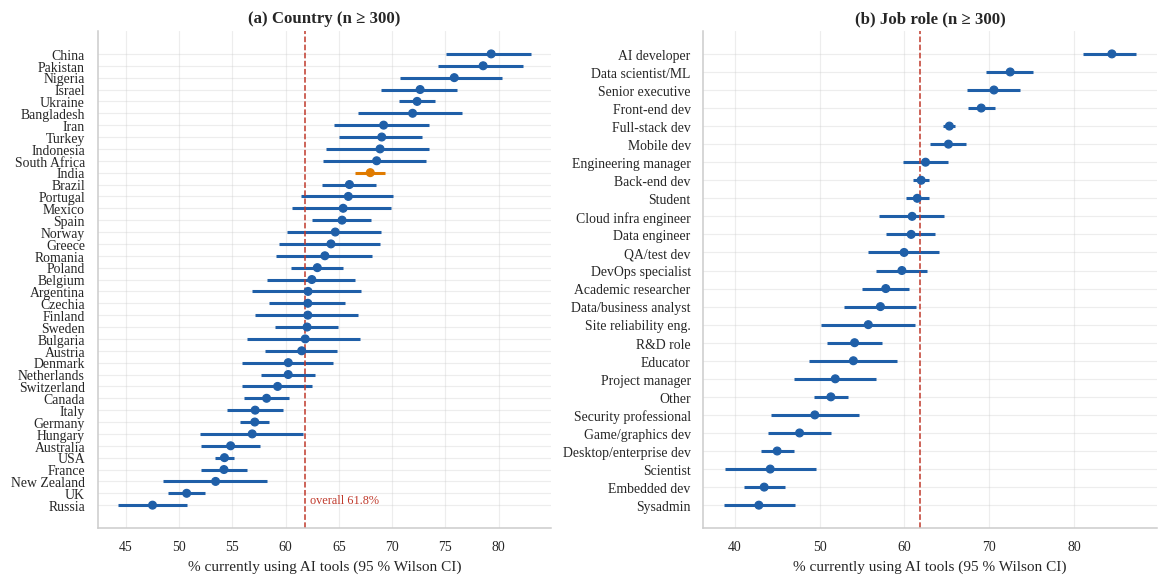

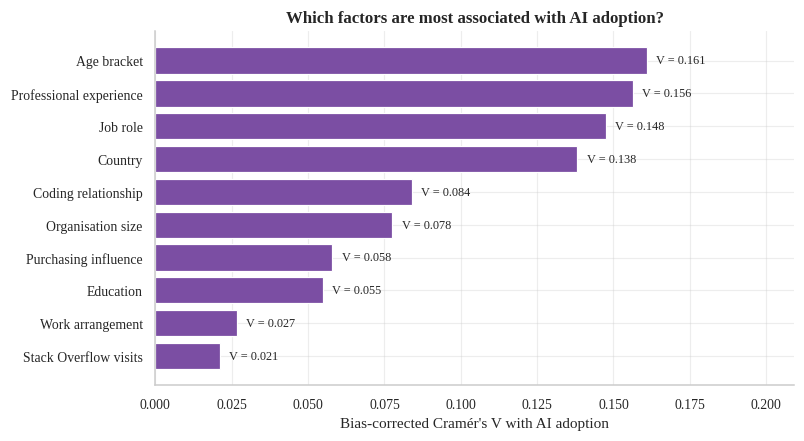

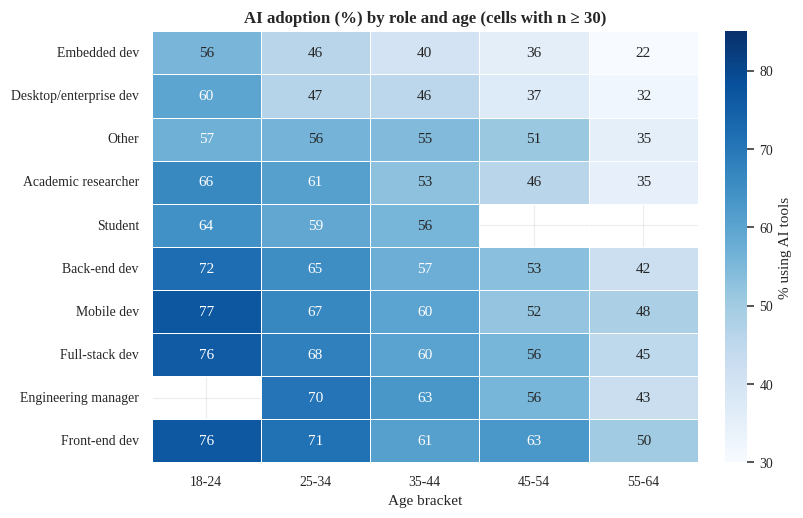

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 5.2))
for ax, f, title in [(axes[0], "country", "(a) Country (n ≥ 300)"), (axes[1], "dev_type", "(b) Job role (n ≥ 300)")]:
    t = rt[f].sort_values("rate"); y = np.arange(len(t))
    col = [PALETTE["orange"] if c == "India" else PALETTE["blue"] for c in t[f]]
    ax.hlines(y, t.lo, t.hi, color=col, lw=2); ax.scatter(t.rate, y, color=col, zorder=3, s=26)
    ax.axvline(overall, color=PALETTE["red"], ls="--", lw=1); ax.set_yticks(y); ax.set_yticklabels(t[f]); ax.set_xlabel("% currently using AI tools (95 % Wilson CI)"); ax.set_title(title)
axes[0].text(overall + .4, 0.2, f"overall {overall:.1f}%", color=PALETTE["red"], fontsize=8)
savefig(fig, "fig17_ai_adoption_country_role", "AI adoption rate with 95 % Wilson CIs by country (a) and job role (b); dashed line = overall adoption; India in orange.", "O4")
plt.show()

fig, ax = plt.subplots(figsize=(7.2, 3.9))
ft = ftab.sort_values("cramers_v"); ax.barh(ft.label, ft.cramers_v, color=PALETTE["purple"])
for i, (v, p_) in enumerate(zip(ft.cramers_v, ft.p)): ax.text(v + .003, i, f"V = {v:.3f}" + ("" if p_ < .001 else f"  (p = {p_:.2f})"), va="center", fontsize=8)
ax.set_xlabel("Bias-corrected Cramér's V with AI adoption"); ax.set_xlim(0, ft.cramers_v.max() * 1.3); ax.set_title("Which factors are most associated with AI adoption?")
savefig(fig, "fig18_ai_cramers_v", "Strength of association (Cramér's V) between AI adoption and each descriptive factor.", "O4")
plt.show()

# heatmap: role x age
top_roles = ai.dev_type.value_counts().head(10).index; ages = [a for a in AGE_ORDER if a in ("18-24", "25-34", "35-44", "45-54", "55-64")]
hm = ai[ai.dev_type.isin(top_roles) & ai.age.isin(ages)].pivot_table(index="dev_type", columns="age", values="uses_ai", aggfunc="mean") * 100
cnt = ai[ai.dev_type.isin(top_roles) & ai.age.isin(ages)].pivot_table(index="dev_type", columns="age", values="uses_ai", aggfunc="count")
hm = hm.where(cnt >= 30).reindex(index=hm.mean(axis=1).sort_values().index, columns=ages)
fig, ax = plt.subplots(figsize=(7.2, 4.6))
sns.heatmap(hm, annot=True, fmt=".0f", cmap="Blues", vmin=30, vmax=85, ax=ax, linewidths=.5, cbar_kws={"label": "% using AI tools"})
ax.set_xlabel("Age bracket"); ax.set_ylabel(""); ax.set_title("AI adoption (%) by role and age (cells with n ≥ 30)")
savefig(fig, "fig19_ai_role_age_heatmap", "AI adoption by job role and age bracket (blank = fewer than 30 respondents).", "O4")
plt.show(); save_results()

## O5 — AI sentiment, trust and job-threat perception
**Research question.** Do favourability, trust in AI accuracy, belief that AI handles complex tasks, and fear of
job loss differ by career stage, role and country? **Data note.** These four questions were asked **only** to
people who use (or plan to use) AI tools, so inference is limited to that population — and, as proven below,
they must not be used as predictors of adoption (leakage). **Methods:** ordinal scores (1–5), Spearman ρ with
CI, Kruskal–Wallis with ε², χ² + Cramér's V for the categorical threat answer, Mann–Whitney for India vs rest.

In [32]:
# --- Proof of structural conditionality (the leakage argument) ---
cond = pd.DataFrame({q: df.groupby(df.ai_select.fillna("(unanswered)"))[q].apply(lambda s: s.notna().mean() * 100) for q in ["ai_sent", "ai_acc", "ai_complex", "ai_threat"]}).round(1)
save_table(cond.reset_index().rename(columns={"ai_select": "ai_select answer"}), "tbl_o5_conditionality", "Share of respondents answering each AI follow-up question, by their AI-use answer (percent)", "O5")
R["O5_conditionality"] = cond.to_dict("index"); cond

,ai_sent,ai_acc,ai_complex,ai_threat
ai_select,,,,
(unanswered),0.000,0.000,0.000,0.000
"No, and I don't plan to",0.000,0.000,0.000,0.000
"No, but I plan to soon",99.200,0.000,0.000,99.400
Yes,99.700,99.000,98.300,96.500


In [33]:
att = df[df.ai_select.isin(["Yes", "No, but I plan to soon"])].copy()
att["sent"] = map_prefix(att.ai_sent, SENT_SCORE); att["trust"] = map_prefix(att.ai_acc, TRUST_SCORE); att["complex_"] = map_prefix(att.ai_complex, COMPLEX_SCORE)
att["threat"] = att.ai_threat.map({"Yes": "Yes", "No": "No", "I'm not sure": "Not sure"})
att["threat_yes"] = np.where(att.threat.isna(), np.nan, (att.threat == "Yes").astype(float))
att["exp_band"] = pd.Categorical(att.exp_band, categories=bands, ordered=True)
dist = {}
for col, lab in [("ai_sent", "Sentiment"), ("ai_acc", "Trust in accuracy"), ("ai_complex", "Complex tasks"), ("ai_threat", "Threat to job")]:
    vc = att[col].value_counts(normalize=True) * 100; dist[lab] = vc.round(1).to_dict()
users = att[att.ai_select == "Yes"]
spr = {}
for v, lab in [("sent", "Favourability"), ("trust", "Trust in AI accuracy"), ("complex_", "AI on complex tasks"), ("threat_yes", "Sees AI as threat (yes=1)")]:
    spr[lab] = dict(exp=spearman(att.years_code_pro, att[v]), age=spearman(att.age_mid, att[v]))
kw = {}
for v, lab in [("sent", "Favourability"), ("trust", "Trust")]:
    gs = [g[v].dropna().values for _, g in att.groupby("exp_band", observed=True) if g[v].notna().sum() > 20]
    Hh, ph = stats.kruskal(*gs); kw[lab] = dict(H=float(Hh), p=float(ph), eps2=epsilon_squared_kruskal(Hh, sum(len(g) for g in gs)))
thr_tab = {}
for f in ["exp_band", "age", "dev_type", "country"]:
    t = att[[f, "threat_yes", "threat"]].dropna()
    if f in ("dev_type", "country"): t = t[t[f].map(t[f].value_counts()) >= 300]
    if f == "age": t = t[t.age != "Prefer not to say"]
    r_ = chi2_test(t[f].astype(str), t["threat"]); thr_tab[f] = r_
ind_t = att[att.country == "India"]; rest_t = att[att.country != "India"]
mw_india = {v: dict(india_mean=float(ind_t[v].mean()), rest_mean=float(rest_t[v].mean()), p=float(stats.mannwhitneyu(ind_t[v].dropna(), rest_t[v].dropna()).pvalue), n=int(ind_t[v].notna().sum())) for v in ["sent", "trust", "complex_"]}
z_thr = two_prop_ztest(ind_t.threat_yes.sum(), ind_t.threat_yes.notna().sum(), rest_t.threat_yes.sum(), rest_t.threat_yes.notna().sum())
um = stats.mannwhitneyu(users.sent.dropna(), att[att.ai_select != "Yes"].sent.dropna())
trust_pos = float(att.trust.dropna().ge(4).mean() * 100); trust_neg = float(att.trust.dropna().le(2).mean() * 100)
R["O5"] = dict(n_att=len(att), n_users=len(users), dist=dist, spearman=spr, kruskal=kw, threat_tests=thr_tab, india=mw_india, india_threat=z_thr,
               users_vs_planners_sent=dict(users_mean=float(users.sent.mean()), planners_mean=float(att[att.ai_select != "Yes"].sent.mean()), p=float(um.pvalue)),
               trust_positive_pct=trust_pos, trust_negative_pct=trust_neg, threat_yes_pct=float(att.threat_yes.mean() * 100),
               fav_pct=float(att.sent.dropna().ge(4).mean() * 100), complex_good_pct=float(att.complex_.dropna().ge(4).mean() * 100), complex_bad_pct=float(att.complex_.dropna().le(2).mean() * 100),
               trust_complex_rho=spearman(att.trust, att.complex_), trust_sent_rho=spearman(att.trust, att.sent))
for k, v in spr.items(): print(f"{k:28s} rho(exp) = {v['exp']['rho']:+.3f}  [{v['exp']['ci_low']:+.3f},{v['exp']['ci_high']:+.3f}] n={v['exp']['n']}")
print({k: round(v, 1) for k, v in R["O5"].items() if isinstance(v, float)})

Favourability                rho(exp) = -0.029  [-0.040,-0.018] n=36930
Trust in AI accuracy         rho(exp) = -0.056  [-0.068,-0.044] n=31049
AI on complex tasks          rho(exp) = -0.028  [-0.039,-0.016] n=30883
Sees AI as threat (yes=1)    rho(exp) = -0.021  [-0.032,-0.011] n=37777
{'trust_positive_pct': 43.0, 'trust_negative_pct': 30.4, 'threat_yes_pct': 12.1, 'fav_pct': 74.2, 'complex_good_pct': 36.0, 'complex_bad_pct': 43.2}


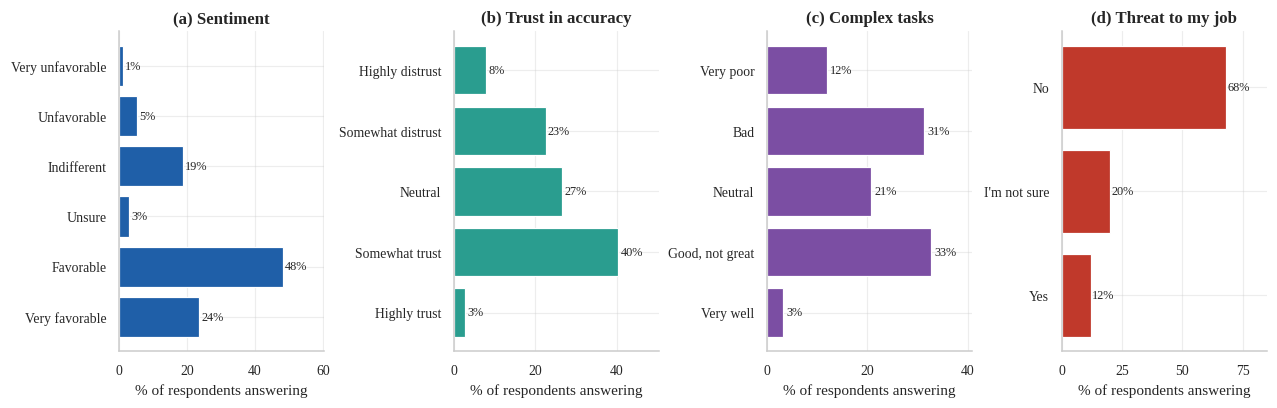

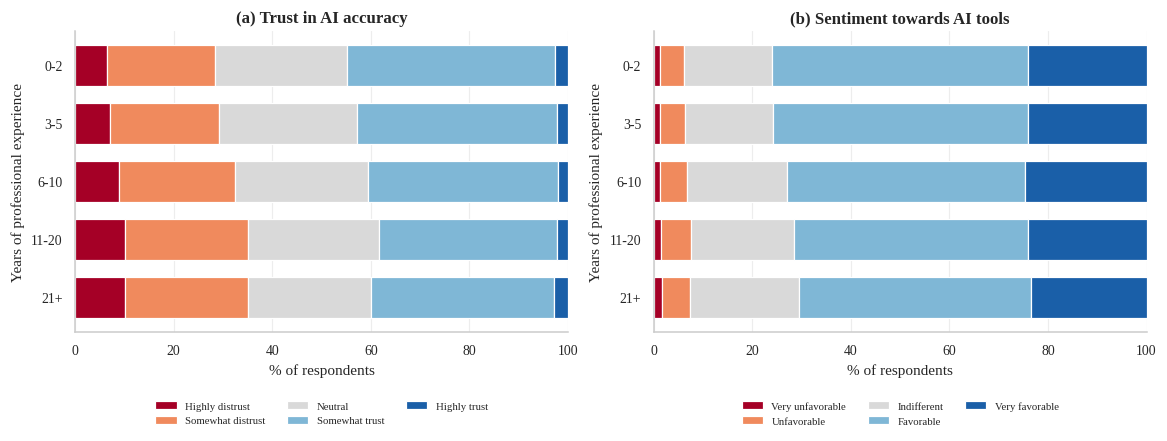

In [34]:
fig, axes = plt.subplots(1, 4, figsize=(11.5, 3.6), sharex=False)
orders = {"ai_sent": ["Very unfavorable", "Unfavorable", "Indifferent", "Unsure", "Favorable", "Very favorable"],
          "ai_acc": ["Highly distrust", "Somewhat distrust", "Neither trust nor distrust", "Somewhat trust", "Highly trust"],
          "ai_complex": ["Very poor at handling complex tasks", "Bad at handling complex tasks", "Neither good or bad at handling complex tasks", "Good, but not great at handling complex tasks", "Very well at handling complex tasks"],
          "ai_threat": ["No", "I'm not sure", "Yes"]}
short = {"Neither trust nor distrust": "Neutral", "Very poor at handling complex tasks": "Very poor", "Bad at handling complex tasks": "Bad",
         "Neither good or bad at handling complex tasks": "Neutral", "Good, but not great at handling complex tasks": "Good, not great", "Very well at handling complex tasks": "Very well"}
for ax, (col, title), c in zip(axes, [("ai_sent", "(a) Sentiment"), ("ai_acc", "(b) Trust in accuracy"), ("ai_complex", "(c) Complex tasks"), ("ai_threat", "(d) Threat to my job")], [PALETTE["blue"], PALETTE["green"], PALETTE["purple"], PALETTE["red"]]):
    vc = att[col].value_counts(normalize=True).reindex(orders[col]).fillna(0) * 100
    ax.barh([short.get(k, k) for k in vc.index], vc.values, color=c)
    for i, v in enumerate(vc.values): ax.text(v + .6, i, f"{v:.0f}%", va="center", fontsize=8)
    ax.set_xlim(0, vc.max() * 1.25); ax.set_title(title); ax.set_xlabel("% of respondents answering"); ax.invert_yaxis()
savefig(fig, "fig20_ai_attitudes_distribution", "Distribution of attitudes towards AI among respondents who use or plan to use AI tools.", "O5")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9))
for ax, v, lab, lv, title in [(axes[0], "ai_acc", "trust", orders["ai_acc"], "(a) Trust in AI accuracy"), (axes[1], "ai_sent", "sent", [o for o in orders["ai_sent"] if o != "Unsure"], "(b) Sentiment towards AI tools")]:
    t = att[att.exp_band.notna() & att[v].isin(lv)]; ct = pd.crosstab(t.exp_band, t[v], normalize="index").reindex(columns=lv).reindex(bands) * 100
    cols = sns.color_palette(SEQ5, len(lv)) if len(lv) == 5 else ["#a50026", "#f08a5d", "#d9d9d9", "#7fb7d6", "#1a5fa8"]
    left = np.zeros(len(ct))
    for c_, col in zip(lv, cols):
        ax.barh(range(len(ct)), ct[c_], left=left, color=col, label=short.get(c_, c_), height=.7); left += ct[c_].values
    ax.set_yticks(range(len(ct))); ax.set_yticklabels(bands); ax.set_ylabel("Years of professional experience"); ax.set_xlabel("% of respondents"); ax.set_title(title); ax.set_xlim(0, 100); ax.invert_yaxis()
    ax.legend(ncol=3, fontsize=7, loc="upper center", bbox_to_anchor=(.5, -.2))
savefig(fig, "fig21_trust_sentiment_by_experience", "Trust in AI accuracy (a) and sentiment (b) across experience bands (100 % stacked; red = negative, blue = positive).", "O5")
plt.show()

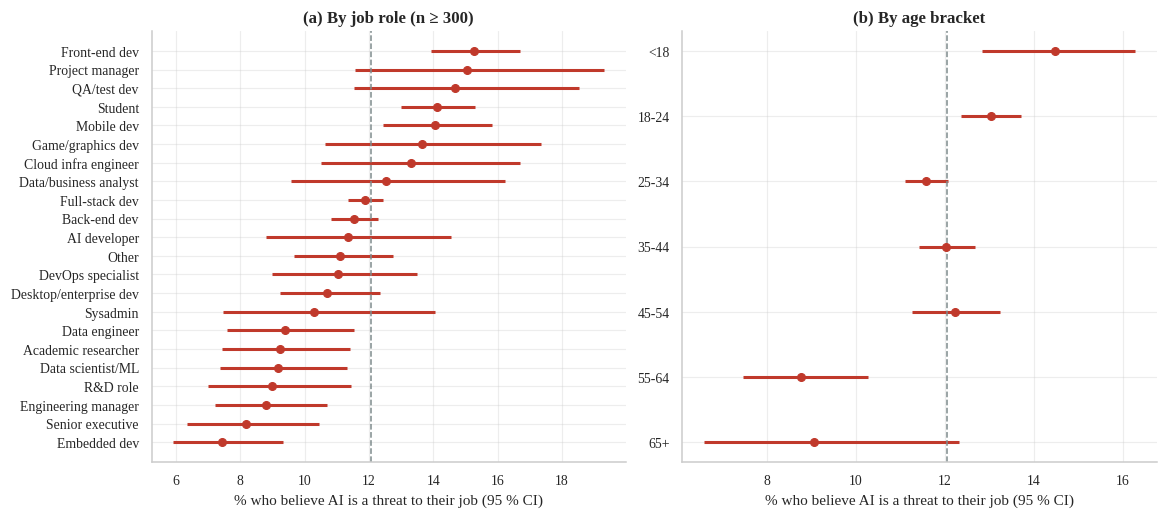

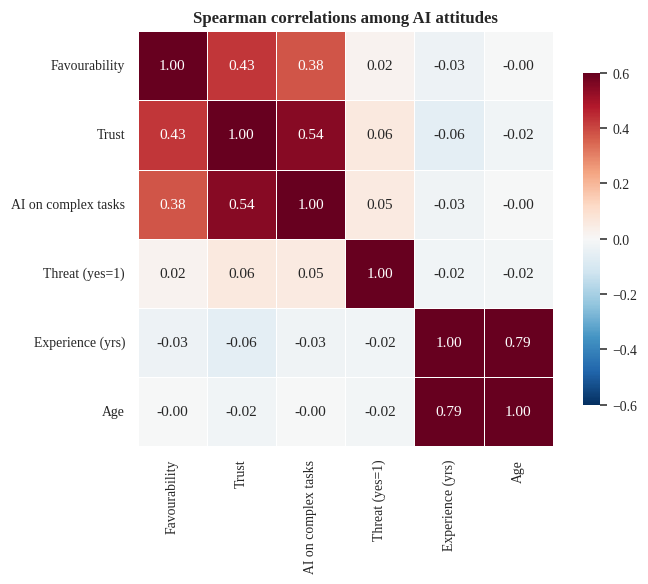

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.6))
for ax, f, title in [(axes[0], "dev_type", "(a) By job role (n ≥ 300)"), (axes[1], "age", "(b) By age bracket")]:
    t = att[[f, "threat_yes"]].dropna()
    if f == "age": t = t[t.age != "Prefer not to say"]
    g = t.groupby(f).threat_yes.agg(["sum", "count"]); g = g[g["count"] >= (300 if f == "dev_type" else 100)]; g["rate"] = g["sum"] / g["count"] * 100
    lo, hi = wilson_ci(g["sum"], g["count"]); g["lo"], g["hi"] = lo * 100, hi * 100
    g = g.sort_values("rate") if f == "dev_type" else g.reindex([a for a in AGE_ORDER if a in g.index])
    y = np.arange(len(g)); ax.hlines(y, g.lo, g.hi, color=PALETTE["red"], lw=2); ax.scatter(g.rate, y, color=PALETTE["red"], zorder=3, s=26)
    ax.axvline(att.threat_yes.mean() * 100, color=PALETTE["grey"], ls="--", lw=1); ax.set_yticks(y); ax.set_yticklabels(g.index); ax.set_xlabel("% who believe AI is a threat to their job (95 % CI)"); ax.set_title(title)
    if f == "age": ax.invert_yaxis()
savefig(fig, "fig22_threat_by_role_age", "Share of respondents who see AI as a threat to their own job, by job role (a) and age (b); dashed line = overall.", "O5")
plt.show()

cm = att[["sent", "trust", "complex_", "threat_yes", "years_code_pro", "age_mid"]].rename(columns={"sent": "Favourability", "trust": "Trust", "complex_": "AI on complex tasks", "threat_yes": "Threat (yes=1)", "years_code_pro": "Experience (yrs)", "age_mid": "Age"}).corr(method="spearman")
fig, ax = plt.subplots(figsize=(6.4, 5.2))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-.6, vmax=.6, square=True, ax=ax, linewidths=.5, cbar_kws={"shrink": .8}); ax.set_title("Spearman correlations among AI attitudes")
savefig(fig, "fig23_attitude_correlations", "Spearman correlation matrix of AI attitude scores with experience and age.", "O5")
plt.show()
R["O5"]["attitude_corr"] = cm.round(3).to_dict()
save_results()

# Part E — Machine learning
## O6 — Predicting annual compensation (regression)
**Prediction task.** Given a professional developer's profile (country, role, experience, company size, education,
work mode, Stack Overflow engagement, AI use) predict annual compensation in USD.
**Target.** $y=\ln(\text{USD})$ — the log transform removes the extreme skew; $\exp(\hat y)$ estimates the *conditional median* pay.

**Metrics.** With residuals $e_i=y_i-\hat y_i$:
$$\text{RMSE}=\sqrt{\tfrac1n\sum e_i^2},\quad \text{MAE}=\tfrac1n\sum|e_i|,\quad R^2=1-\frac{\sum e_i^2}{\sum (y_i-\bar y)^2},\quad
\text{MdAPE}=\operatorname{median}\Big|\tfrac{\hat{\text{USD}}_i-\text{USD}_i}{\text{USD}_i}\Big|$$
**Leakage prevention.** (i) `comp_total` (the local-currency twin of the target) and `currency` are excluded;
(ii) imputers, scalers, one-hot vocabularies and **target encoders are fitted inside a `Pipeline`**, i.e. on the training
part of each CV fold only; (iii) the 20 % hold-out test set is used **once**, after all tuning.
**Success criterion (set in advance):** the best model must cut the baseline RMSE(log) by **≥ 40 %** and beat the
domain-aware *country-median* baseline.

In [36]:
lk = pd.DataFrame([(k, v) for k, v in LEAKAGE_REGISTER.items()], columns=["column", "reason excluded / restricted"])
save_table(lk, "tbl_leakage_register", "Columns excluded from predictors and the reason (leakage register)", "O6")
lk

,column,reason excluded / restricted
0,comp_total,Local-currency twin of the target (converted_c...
1,converted_comp_yearly,Target of the salary task.
2,log_comp,Transform of the target.
3,currency,Near-duplicate of country (information already...
4,response_id,Identifier - no predictive meaning.
5,survey_length,Opinion about the survey itself - unrelated to...
6,survey_ease,Opinion about the survey itself - unrelated to...
7,ai_sent,"Asked ONLY if ai_select in {Yes, plan to} -> i..."
8,ai_acc,Asked ONLY if ai_select = Yes -> reveals the t...
9,ai_complex,Asked ONLY if ai_select = Yes -> reveals the t...


In [37]:
X_all = model_frame(cohort, SALARY_SPEC); y_all = cohort.log_comp
strat = cohort.country.where(cohort.country.isin(cohort.country.value_counts().head(8).index), "Other")
X_tr, X_te, y_tr, y_te = train_test_split(X_all, y_all, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=strat)
print("train", X_tr.shape, "test", X_te.shape, "| predictors:", X_all.shape[1])
R["O6_setup"] = dict(n_train=len(X_tr), n_test=len(X_te), n_features_raw=int(X_all.shape[1]), n_cv_folds=CV_FOLDS)

train (16635, 21) test (4159, 21) | predictors: 21


In [38]:
t0 = time.time()
zoo_r = regression_zoo(SALARY_SPEC)
fit_r, cmp_r, bp_r, folds_r = tune_and_compare(zoo_r, X_tr, y_tr, "regression", n_iter=8, tune_cv=3, eval_cv=CV_FOLDS)
print(f"total {time.time()-t0:.0f}s")
cmp_r

  Baseline: global median      rmse=1.0649  mae=0.7541  r2=-0.0346  [0s]


  Baseline: country median     rmse=0.7632  mae=0.5238  r2=0.4685  [0s]


  Ridge regression             rmse=0.6631  mae=0.4506  r2=0.5988  [7s]


  Random Forest                rmse=0.6472  mae=0.4282  r2=0.6178  [95s]


  HistGradientBoosting         rmse=0.6405  mae=0.4238  r2=0.6256  [42s]


  LightGBM                     rmse=0.6386  mae=0.4223  r2=0.6279  [28s]


total 172s


,model,cv_rmse_mean,cv_rmse_std,cv_mae_mean,cv_mae_std,cv_r2_mean,cv_r2_std,seconds
0,Baseline: global median,1.065,0.013,0.754,0.010,-0.035,0.004,0.056
1,Baseline: country median,0.763,0.015,0.524,0.011,0.468,0.013,0.095
2,Ridge regression,0.663,0.011,0.451,0.007,0.599,0.006,6.893
3,Random Forest,0.647,0.008,0.428,0.004,0.618,0.008,95.124
4,HistGradientBoosting,0.641,0.009,0.424,0.005,0.626,0.008,41.831
5,LightGBM,0.639,0.008,0.422,0.005,0.628,0.007,27.690


In [39]:
# Hold-out evaluation (test set touched ONCE) --------------------------------------------------
test_rows = []; preds_te = {}
for name, m in fit_r.items():
    p_ = m.predict(X_te); preds_te[name] = p_
    test_rows.append({"model": name, **reg_metrics(y_te, p_)})
test_r = pd.DataFrame(test_rows)
comp_r = cmp_r.merge(test_r, on="model").rename(columns={"R2": "test_R2", "RMSE_log": "test_RMSE_log", "MAE_log": "test_MAE_log", "MAE_USD": "test_MAE_USD", "MdAPE_pct": "test_MdAPE_pct", "Within25_pct": "test_Within25_pct"})
comp_r["tuned_params"] = comp_r.model.map(lambda k: json.dumps(bp_r[k]) if bp_r[k] else "-")
save_table(comp_r.round(4), "tbl_o6_model_comparison", "Regression models: 5-fold CV (train) and hold-out test metrics", "O6")
best_name = comp_r.sort_values("cv_rmse_mean").iloc[0].model
second_name = comp_r[~comp_r.model.str.startswith("Baseline")].sort_values("cv_rmse_mean").iloc[1].model
base_rmse = comp_r.set_index("model").loc["Baseline: global median", "test_RMSE_log"]; best_rmse = comp_r.set_index("model").loc[best_name, "test_RMSE_log"]
cm_rmse = comp_r.set_index("model").loc["Baseline: country median", "test_RMSE_log"]
print("BEST (lowest CV RMSE):", best_name, "| runner-up:", second_name)
print(f"RMSE reduction vs global-median baseline: {100*(1-best_rmse/base_rmse):.1f}%  (target >= 40%) | vs country-median: {100*(1-best_rmse/cm_rmse):.1f}%")
comp_r[["model", "cv_rmse_mean", "cv_rmse_std", "cv_r2_mean", "test_R2", "test_RMSE_log", "test_MAE_USD", "test_MdAPE_pct", "test_Within25_pct"]].round(3)

BEST (lowest CV RMSE): LightGBM | runner-up: HistGradientBoosting
RMSE reduction vs global-median baseline: 39.7%  (target >= 40%) | vs country-median: 15.3%


,model,cv_rmse_mean,cv_rmse_std,cv_r2_mean,test_R2,test_RMSE_log,test_MAE_USD,test_MdAPE_pct,test_Within25_pct
0,Baseline: global median,1.065,0.013,-0.035,-0.031,1.048,"49,965.493",48.836,25.727
1,Baseline: country median,0.763,0.015,0.468,0.476,0.747,"34,722.371",34.545,37.172
2,Ridge regression,0.663,0.011,0.599,0.602,0.651,"29,658.966",29.360,44.602
3,Random Forest,0.647,0.008,0.618,0.619,0.637,"28,922.605",27.227,46.381
4,HistGradientBoosting,0.641,0.009,0.626,0.623,0.634,"28,817.298",27.557,46.285
5,LightGBM,0.639,0.008,0.628,0.624,0.633,"28,584.502",27.395,46.550


In [40]:
# Uncertainty: bootstrap CI of test metrics for the best model + paired bootstrap vs runner-up --------------
rng = np.random.default_rng(RANDOM_STATE); yt = y_te.values
e_b = yt - preds_te[best_name]; e_s = yt - preds_te[second_name]
idx = rng.integers(0, len(yt), (2000, len(yt)))
rmse_bs = np.sqrt((e_b[idx] ** 2).mean(1)); r2_bs = 1 - (e_b[idx] ** 2).sum(1) / ((yt[idx] - yt[idx].mean(1, keepdims=True)) ** 2).sum(1)
diff_bs = (e_s[idx] ** 2).mean(1) - (e_b[idx] ** 2).mean(1)             # >0  => best model has lower MSE
R["O6"] = dict(best=best_name, runner_up=second_name, comparison=comp_r.round(4).to_dict("records"), best_params=bp_r,
               rmse_reduction_vs_global_pct=float(100 * (1 - best_rmse / base_rmse)), rmse_reduction_vs_country_pct=float(100 * (1 - best_rmse / cm_rmse)),
               test_rmse_ci=[float(np.percentile(rmse_bs, 2.5)), float(np.percentile(rmse_bs, 97.5))], test_r2_ci=[float(np.percentile(r2_bs, 2.5)), float(np.percentile(r2_bs, 97.5))],
               paired_mse_diff_ci=[float(np.percentile(diff_bs, 2.5)), float(np.percentile(diff_bs, 97.5))], paired_diff_prob_best_better=float((diff_bs > 0).mean()),
               fold_scores=folds_r, success_rmse_cut_40=bool(100 * (1 - best_rmse / base_rmse) >= 40), success_beats_country_median=bool(best_rmse < cm_rmse))
print({k: v for k, v in R["O6"].items() if k not in ("comparison", "best_params", "fold_scores")})

{'best': 'LightGBM', 'runner_up': 'HistGradientBoosting', 'rmse_reduction_vs_global_pct': 39.654495991562776, 'rmse_reduction_vs_country_pct': 15.309061496822107, 'test_rmse_ci': [0.6069122398906314, 0.6608706604322693], 'test_r2_ci': [0.6002161899876112, 0.6464859113220675], 'paired_mse_diff_ci': [-0.0020924592818817494, 0.005179325530513918], 'paired_diff_prob_best_better': 0.8005, 'success_rmse_cut_40': False, 'success_beats_country_median': True}


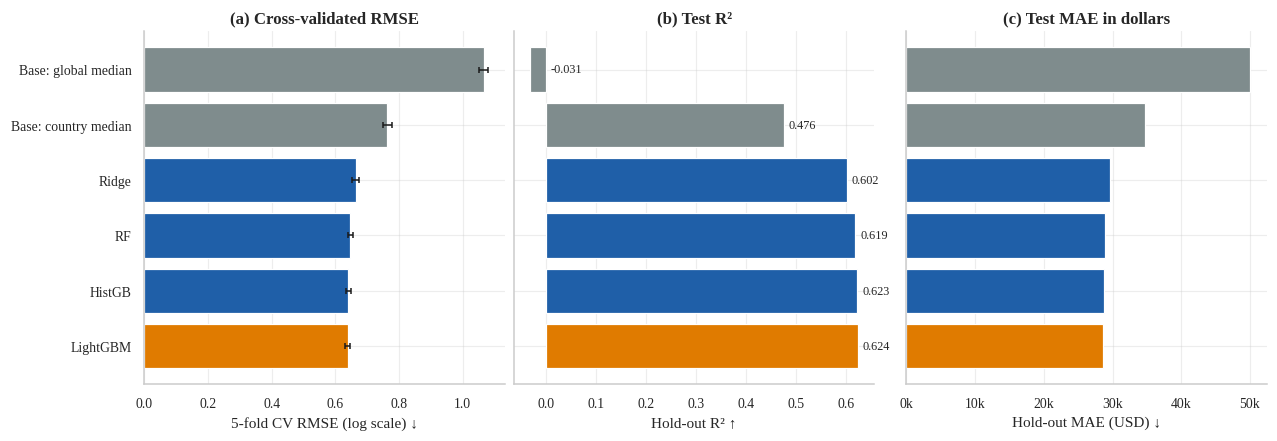

In [41]:
# Model comparison figure ---------------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.9))
cr = comp_r.copy(); cr["short"] = cr.model.str.replace("Baseline: ", "Base: ", regex=False).str.replace("HistGradientBoosting", "HistGB").str.replace("Random Forest", "RF").str.replace("Ridge regression", "Ridge")
colr = [PALETTE["grey"] if m.startswith("Base") else (PALETTE["orange"] if m == best_name else PALETTE["blue"]) for m in cr.model]
axes[0].barh(cr.short, cr.cv_rmse_mean, xerr=cr.cv_rmse_std, color=colr, error_kw=dict(capsize=2, lw=1)); axes[0].set_xlabel("5-fold CV RMSE (log scale) ↓"); axes[0].set_title("(a) Cross-validated RMSE")
axes[1].barh(cr.short, cr.test_R2, color=colr); axes[1].set_xlabel("Hold-out R² ↑"); axes[1].set_title("(b) Test R²"); axes[1].set_yticklabels([])
for i, v in enumerate(cr.test_R2): axes[1].text(max(v, 0) + .01, i, f"{v:.3f}", va="center", fontsize=8)
axes[2].barh(cr.short, cr.test_MAE_USD, color=colr); axes[2].set_xlabel("Hold-out MAE (USD) ↓"); axes[2].set_title("(c) Test MAE in dollars"); axes[2].set_yticklabels([])
axes[2].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))
for ax in axes: ax.invert_yaxis()
savefig(fig, "fig24_regression_model_comparison", "Regression model comparison: cross-validated RMSE with ±1 SD (a), hold-out R² (b) and hold-out MAE in USD (c). Grey = baselines, orange = selected model.", "O6")
plt.show()

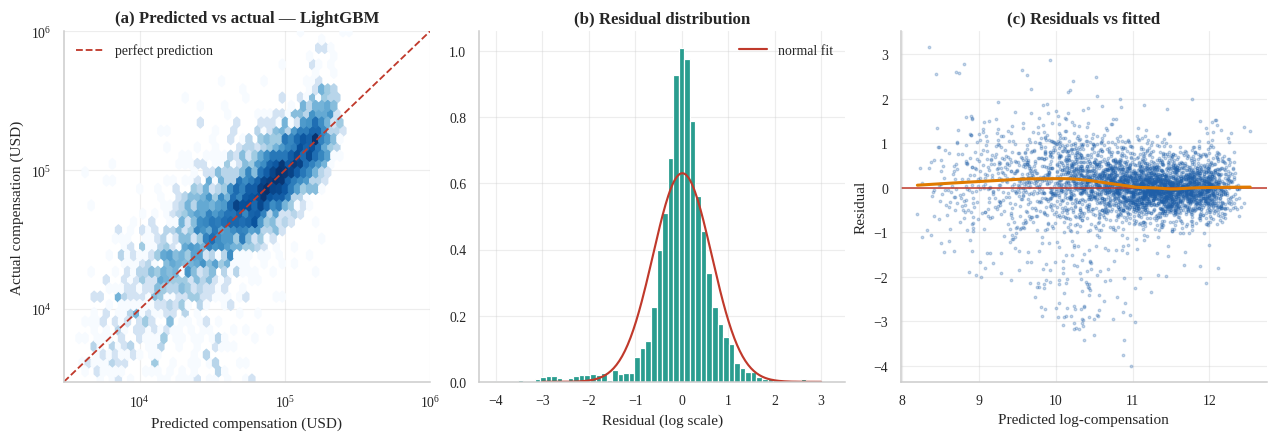

{'mean': 0.014000178675476089, 'sd': 0.6324084533713652, 'skew': -1.084168549313548, 'kurt': 6.027004312614665, 'shapiro_p': 1.3550461866283632e-46}


In [42]:
best_r = fit_r[best_name]; p_best = preds_te[best_name]
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.9))
hb = axes[0].hexbin(np.exp(p_best), np.exp(y_te), gridsize=45, xscale="log", yscale="log", cmap="Blues", mincnt=1, bins="log")
lims = [3e3, 1e6]; axes[0].plot(lims, lims, color=PALETTE["red"], lw=1.2, ls="--", label="perfect prediction"); axes[0].set_xlim(lims); axes[0].set_ylim(lims)
axes[0].set_xlabel("Predicted compensation (USD)"); axes[0].set_ylabel("Actual compensation (USD)"); axes[0].set_title(f"(a) Predicted vs actual — {best_name}"); axes[0].legend(loc="upper left")
resid = y_te.values - p_best
axes[1].hist(resid, bins=60, color=PALETTE["green"], density=True); xs_ = np.linspace(-3, 3, 200); axes[1].plot(xs_, stats.norm.pdf(xs_, resid.mean(), resid.std()), color=PALETTE["red"], lw=1.4, label="normal fit")
axes[1].set_xlabel("Residual (log scale)"); axes[1].set_title("(b) Residual distribution"); axes[1].legend()
axes[2].scatter(p_best, resid, s=3, alpha=.25, color=PALETTE["blue"]); axes[2].axhline(0, color=PALETTE["red"], lw=1)
sm_ = lw.lowess(resid, p_best, frac=.3); axes[2].plot(sm_[:, 0], sm_[:, 1], color=PALETTE["orange"], lw=2)
axes[2].set_xlabel("Predicted log-compensation"); axes[2].set_ylabel("Residual"); axes[2].set_title("(c) Residuals vs fitted")
savefig(fig, "fig25_regression_diagnostics", "Diagnostics of the selected regression model on the hold-out set: predicted vs actual pay (a), residual distribution (b) and residuals vs fitted values with LOWESS (c).", "O6")
plt.show()
R["O6"]["residual"] = dict(mean=float(resid.mean()), sd=float(resid.std()), skew=float(stats.skew(resid)), kurt=float(stats.kurtosis(resid)), shapiro_p=float(stats.shapiro(resid[:5000]).pvalue))
print(R["O6"]["residual"])

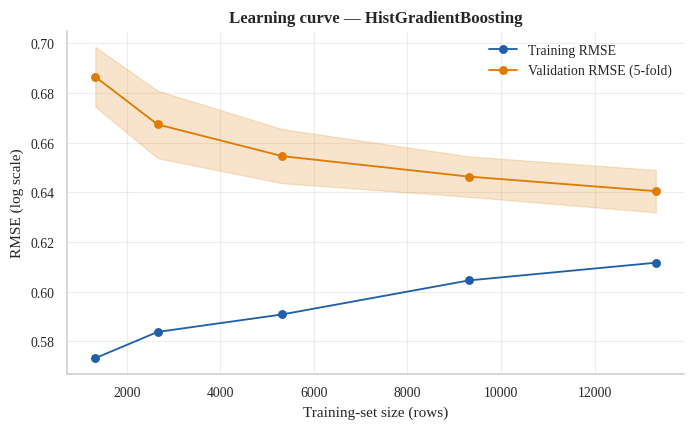

,policy,n,cv_rmse_log,cv_r2,cv_mae_log
0,Absolute bounds only (USD 1k–1M),21007,0.673,0.602,0.442
1,Country 3×IQR (chosen),20796,0.637,0.627,0.420
2,Country 1.5×IQR (strict),20136,0.583,0.661,0.388


In [43]:
# Outlier-policy sensitivity (design-decision check) and learning curve ---------------------------------------------
from sklearn.model_selection import learning_curve
hgb_params = bp_r["HistGradientBoosting"]; sens = []
for label, kw_ in [("Absolute bounds only (USD 1k–1M)", dict(policy="bounds")), ("Country 3×IQR (chosen)", dict(policy="country_iqr", k=3.0)), ("Country 1.5×IQR (strict)", dict(policy="country_iqr", k=1.5))]:
    c_, _ = build_salary_cohort(add_features(decode(df_raw, crosswalk)), **kw_)
    Xs_, ys_ = model_frame(c_, SALARY_SPEC), c_.log_comp
    mdl = clone(zoo_r["HistGradientBoosting"][0]).set_params(**hgb_params)
    cvr = cross_validate(mdl, Xs_, ys_, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE), scoring={"rmse": "neg_root_mean_squared_error", "r2": "r2", "mae": "neg_mean_absolute_error"})
    sens.append(dict(policy=label, n=len(c_), cv_rmse_log=-cvr["test_rmse"].mean(), cv_r2=cvr["test_r2"].mean(), cv_mae_log=-cvr["test_mae"].mean()))
sens = pd.DataFrame(sens); save_table(sens.round(4), "tbl_o6_outlier_sensitivity", "Sensitivity of HistGradientBoosting CV performance to the outlier policy", "O6"); R["O6"]["sensitivity"] = sens.round(4).to_dict("records")
mdl = clone(zoo_r["HistGradientBoosting"][0]).set_params(**hgb_params)
ts, tr_s, va_s = learning_curve(mdl, X_tr, y_tr, train_sizes=[.1, .2, .4, .7, 1.0], cv=KFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="neg_root_mean_squared_error")
R["O6"]["learning_curve"] = dict(sizes=ts.tolist(), train=(-tr_s.mean(1)).tolist(), val=(-va_s.mean(1)).tolist(), val_sd=va_s.std(1).tolist())
fig, ax = plt.subplots(figsize=(6.2, 3.8))
ax.plot(ts, -tr_s.mean(1), "o-", color=PALETTE["blue"], label="Training RMSE"); ax.plot(ts, -va_s.mean(1), "o-", color=PALETTE["orange"], label="Validation RMSE (5-fold)")
ax.fill_between(ts, -va_s.mean(1) - va_s.std(1), -va_s.mean(1) + va_s.std(1), color=PALETTE["orange"], alpha=.2)
ax.set_xlabel("Training-set size (rows)"); ax.set_ylabel("RMSE (log scale)"); ax.set_title("Learning curve — HistGradientBoosting"); ax.legend()
savefig(fig, "fig26_learning_curve", "Learning curve of the tuned gradient-boosting model: the validation error is still slowly falling, so more data would help slightly.", "O6")
plt.show(); sens

In [44]:
joblib.dump(best_r, MODEL_DIR / "best_salary_model.joblib")
joblib.dump(fit_r, MODEL_DIR / "all_salary_models.joblib")
X_te.assign(actual_log=y_te.values, pred_log=p_best).to_csv(RES_DIR / "salary_test_predictions.csv")
save_results(); print("saved:", best_name)

saved: LightGBM


## O7 — Predicting AI-tool adoption (binary classification)
**Prediction task.** Will a developer currently use AI tools in their workflow? (`uses_ai` = 1 if `ai_select = "Yes"`,
else 0). Population: all 60 907 respondents with a known answer.

**Metrics.** With TP/FP/TN/FN: $\text{Precision}=\frac{TP}{TP+FP}$, $\text{Recall}=\frac{TP}{TP+FN}$,
$F_1=\frac{2PR}{P+R}$, ROC-AUC = $P(\hat p_{pos}>\hat p_{neg})$, PR-AUC = area under precision–recall curve,
Brier = $\frac1n\sum(\hat p_i-y_i)^2$ (calibration). **Baseline:** always predict the majority class.
**Success criterion (set in advance):** ROC-AUC ≥ 0.65 on the hold-out set, and F1 above the majority baseline.

### Leakage demonstration (why `ai_sent`, `ai_acc`, `ai_complex`, `ai_threat` are forbidden here)
Their *presence* reveals the target (see O5 conditionality table). We train one quick model **with** and **without**
them to measure how misleading a leaky evaluation would be.

In [45]:
X_a = model_frame(ai_cohort, ADOPT_SPEC); y_a = ai_cohort.uses_ai.astype(int)
X_atr, X_ate, y_atr, y_ate = train_test_split(X_a, y_a, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y_a)
print("train", X_atr.shape, "test", X_ate.shape, "| positive rate train %.3f / test %.3f" % (y_atr.mean(), y_ate.mean()))
leak_cols = ["ai_sent", "ai_acc", "ai_complex", "ai_threat"]
leaky_spec = dict(ADOPT_SPEC, low=ADOPT_SPEC["low"] + leak_cols)
Xl = model_frame(ai_cohort, leaky_spec)
Xl_tr, Xl_te = Xl.loc[X_atr.index], Xl.loc[X_ate.index]
def quick(spec, Xtr_, Xte_):
    m = Pipeline([("pre", make_preprocessor("tree", spec, "binary")), ("m", HistGradientBoostingClassifier(random_state=RANDOM_STATE))]).fit(Xtr_, y_atr)
    return roc_auc_score(y_ate, m.predict_proba(Xte_)[:, 1])
auc_honest, auc_leaky = quick(ADOPT_SPEC, X_atr, X_ate), quick(leaky_spec, Xl_tr, Xl_te)
R["O7_leakage_demo"] = dict(auc_honest=float(auc_honest), auc_leaky=float(auc_leaky))
print(f"Test ROC-AUC without leaky columns = {auc_honest:.3f}  |  WITH conditional AI-question columns = {auc_leaky:.3f}  (inflated by {auc_leaky-auc_honest:+.3f})")

train (48725, 21) test (12182, 21) | positive rate train 0.618 / test 0.618


Test ROC-AUC without leaky columns = 0.665  |  WITH conditional AI-question columns = 1.000  (inflated by +0.335)


In [46]:
t0 = time.time()
zoo_c = classification_zoo(ADOPT_SPEC)
fit_c, cmp_c, bp_c, folds_c = tune_and_compare(zoo_c, X_atr, y_atr, "classification", n_iter=8, tune_cv=3, eval_cv=CV_FOLDS)
print(f"total {time.time()-t0:.0f}s"); cmp_c

  Baseline: majority class     roc_auc=0.5000  f1=0.7642  accuracy=0.6183  [0s]


  Logistic Regression          roc_auc=0.6664  f1=0.7545  accuracy=0.6514  [54s]


  Random Forest                roc_auc=0.6629  f1=0.7561  accuracy=0.6501  [310s]


  HistGradientBoosting         roc_auc=0.6689  f1=0.7562  accuracy=0.6527  [92s]


  LightGBM                     roc_auc=0.6707  f1=0.7553  accuracy=0.6532  [84s]


total 540s


,model,cv_roc_auc_mean,cv_roc_auc_std,cv_f1_mean,cv_f1_std,cv_accuracy_mean,cv_accuracy_std,seconds
0,Baseline: majority class,0.500,0.000,0.764,0.000,0.618,0.000,0.199
1,Logistic Regression,0.666,0.008,0.754,0.005,0.651,0.006,53.731
2,Random Forest,0.663,0.006,0.756,0.004,0.650,0.005,310.234
3,HistGradientBoosting,0.669,0.006,0.756,0.003,0.653,0.004,92.173
4,LightGBM,0.671,0.006,0.755,0.003,0.653,0.004,84.057


In [47]:
test_rows, proba_te = [], {}
for name, m in fit_c.items():
    pr = m.predict_proba(X_ate)[:, 1]; proba_te[name] = pr
    test_rows.append({"model": name, **clf_metrics(y_ate, pr, 0.5)})
test_c = pd.DataFrame(test_rows)
comp_c = cmp_c.merge(test_c, on="model").rename(columns={c: f"test_{c}" for c in test_c.columns if c != "model"})
comp_c["tuned_params"] = comp_c.model.map(lambda k: json.dumps(bp_c[k]) if bp_c[k] else "-")
save_table(comp_c.round(4), "tbl_o7_model_comparison", "Classification models: 5-fold CV (train) and hold-out test metrics", "O7")
best_c_name = comp_c.sort_values("cv_roc_auc_mean", ascending=False).iloc[0].model
best_c = fit_c[best_c_name]
# F1-optimal threshold chosen on OUT-OF-FOLD train predictions only (no test peeking)
oof = cross_val_predict(best_c, X_atr, y_atr, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), method="predict_proba")[:, 1]
from sklearn.metrics import balanced_accuracy_score
ths = np.linspace(.2, .8, 61); f1s = [f1_score(y_atr, oof >= t) for t in ths]; thr_opt = float(ths[int(np.argmax(f1s))])
bals = [balanced_accuracy_score(y_atr, oof >= t) for t in ths]; thr_bal = float(ths[int(np.argmax(bals))])   # balanced-accuracy (Youden-type) operating point
m05 = clf_metrics(y_ate, proba_te[best_c_name], 0.5); mopt = clf_metrics(y_ate, proba_te[best_c_name], thr_opt); mbal = clf_metrics(y_ate, proba_te[best_c_name], thr_bal)
rng = np.random.default_rng(RANDOM_STATE); pt = proba_te[best_c_name]; yt_ = y_ate.values; bs = []
for _ in range(1000):
    i = rng.integers(0, len(yt_), len(yt_)); bs.append(roc_auc_score(yt_[i], pt[i]))
base_f1 = comp_c.set_index("model").loc["Baseline: majority class", "test_F1"]
R["O7"] = dict(best=best_c_name, comparison=comp_c.round(4).to_dict("records"), best_params=bp_c, threshold_opt=thr_opt, threshold_bal=thr_bal, metrics_at_05=m05, metrics_at_opt=mopt, metrics_at_bal=mbal,
               auc_ci=[float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5))], fold_scores=folds_c, positive_rate=float(y_a.mean()),
               n_train=len(X_atr), n_test=len(X_ate), success_auc_065=bool(m05["ROC_AUC"] >= 0.65), success_f1_at_05=bool(m05["F1"] > base_f1), success_f1_at_opt=bool(mopt["F1"] > base_f1), baseline_f1=float(base_f1))
print("BEST:", best_c_name, "| threshold (F1-opt on OOF) =", thr_opt)
print("balanced thr =", thr_bal, {k: round(v, 3) for k, v in mbal.items()}); print("default 0.5 :", {k: round(v, 3) for k, v in m05.items()}); print("tuned thr   :", {k: round(v, 3) for k, v in mopt.items()})
comp_c[["model", "cv_roc_auc_mean", "cv_roc_auc_std", "test_Accuracy", "test_Precision", "test_Recall", "test_F1", "test_ROC_AUC", "test_PR_AUC", "test_Brier"]].round(3)

BEST: LightGBM | threshold (F1-opt on OOF) = 0.38000000000000006
balanced thr = 0.6200000000000001 {'Accuracy': 0.618, 'BalAcc': 0.622, 'Precision': 0.731, 'Recall': 0.605, 'F1': 0.662, 'ROC_AUC': 0.669, 'PR_AUC': 0.755, 'Brier': 0.216}
default 0.5 : {'Accuracy': 0.655, 'BalAcc': 0.589, 'Precision': 0.671, 'Recall': 0.867, 'F1': 0.756, 'ROC_AUC': 0.669, 'PR_AUC': 0.755, 'Brier': 0.216}
tuned thr   : {'Accuracy': 0.642, 'BalAcc': 0.541, 'Precision': 0.639, 'Recall': 0.968, 'F1': 0.77, 'ROC_AUC': 0.669, 'PR_AUC': 0.755, 'Brier': 0.216}


,model,cv_roc_auc_mean,cv_roc_auc_std,test_Accuracy,test_Precision,test_Recall,test_F1,test_ROC_AUC,test_PR_AUC,test_Brier
0,Baseline: majority class,0.500,0.000,0.618,0.618,1.000,0.764,0.500,0.618,0.236
1,Logistic Regression,0.666,0.008,0.655,0.670,0.871,0.758,0.666,0.753,0.217
2,Random Forest,0.663,0.006,0.649,0.665,0.872,0.755,0.659,0.747,0.218
3,HistGradientBoosting,0.669,0.006,0.652,0.669,0.866,0.755,0.664,0.751,0.217
4,LightGBM,0.671,0.006,0.655,0.671,0.867,0.756,0.669,0.755,0.216


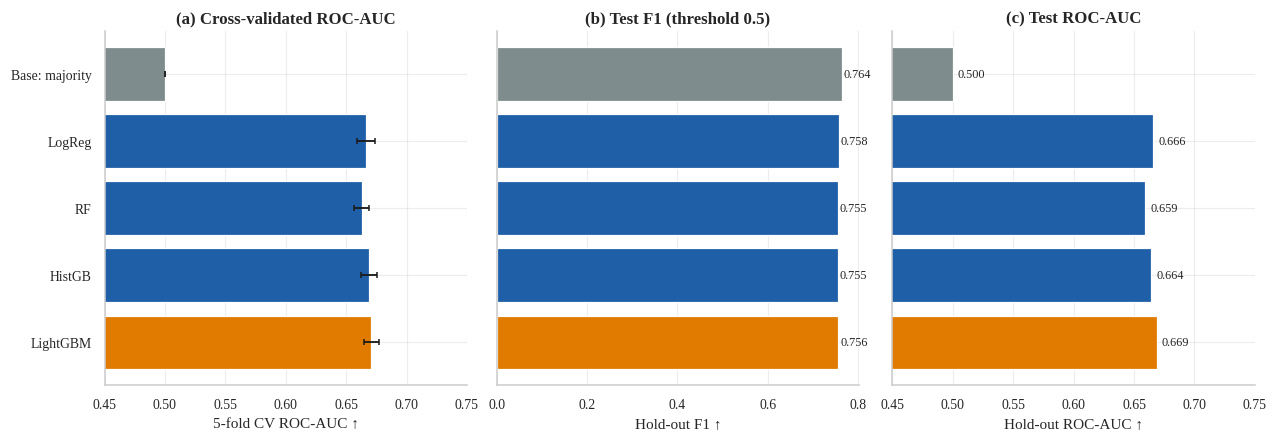

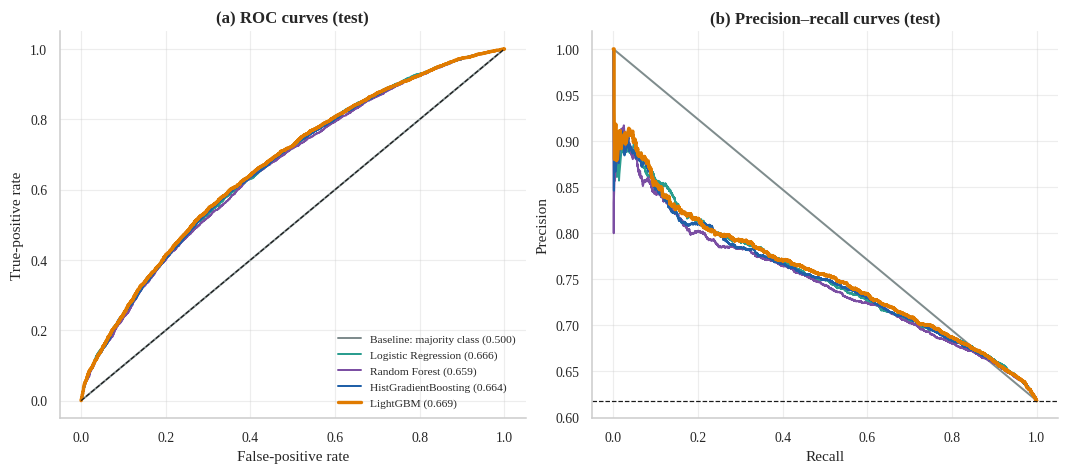

In [48]:
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix
from sklearn.calibration import calibration_curve
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.9))
cc_ = comp_c.copy(); cc_["short"] = cc_.model.str.replace("Baseline: majority class", "Base: majority").str.replace("HistGradientBoosting", "HistGB").str.replace("Random Forest", "RF").str.replace("Logistic Regression", "LogReg")
colc = [PALETTE["grey"] if m.startswith("Base") else (PALETTE["orange"] if m == best_c_name else PALETTE["blue"]) for m in cc_.model]
axes[0].barh(cc_.short, cc_.cv_roc_auc_mean, xerr=cc_.cv_roc_auc_std, color=colc, error_kw=dict(capsize=2)); axes[0].set_xlim(.45, .75); axes[0].set_xlabel("5-fold CV ROC-AUC ↑"); axes[0].set_title("(a) Cross-validated ROC-AUC")
axes[1].barh(cc_.short, cc_.test_F1, color=colc); axes[1].set_xlabel("Hold-out F1 ↑"); axes[1].set_title("(b) Test F1 (threshold 0.5)"); axes[1].set_yticklabels([])
axes[2].barh(cc_.short, cc_.test_ROC_AUC, color=colc); axes[2].set_xlim(.45, .75); axes[2].set_xlabel("Hold-out ROC-AUC ↑"); axes[2].set_title("(c) Test ROC-AUC"); axes[2].set_yticklabels([])
for a_, col in [(axes[1], "test_F1"), (axes[2], "test_ROC_AUC")]:
    for i, v in enumerate(cc_[col]): a_.text(v + .004, i, f"{v:.3f}", va="center", fontsize=8)
for ax in axes: ax.invert_yaxis()
savefig(fig, "fig27_classification_model_comparison", "Classification model comparison: cross-validated ROC-AUC (a), hold-out F1 (b) and hold-out ROC-AUC (c). Grey = baseline, orange = selected model.", "O7")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.2))
for (name, pr), col in zip(proba_te.items(), [PALETTE["grey"], PALETTE["green"], PALETTE["purple"], PALETTE["blue"], PALETTE["orange"]]):
    fpr, tpr, _ = roc_curve(y_ate, pr); axes[0].plot(fpr, tpr, color=col, lw=2.2 if name == best_c_name else 1.3, label=f"{name} ({roc_auc_score(y_ate, pr):.3f})")
    p_, r_, _ = precision_recall_curve(y_ate, pr); axes[1].plot(r_, p_, color=col, lw=2.2 if name == best_c_name else 1.3)
axes[0].plot([0, 1], [0, 1], "k--", lw=.8); axes[0].set_xlabel("False-positive rate"); axes[0].set_ylabel("True-positive rate"); axes[0].set_title("(a) ROC curves (test)"); axes[0].legend(fontsize=7.5, loc="lower right")
axes[1].axhline(y_ate.mean(), color="k", ls="--", lw=.8); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("(b) Precision–recall curves (test)")
savefig(fig, "fig28_roc_pr_curves", "ROC curves with AUC in the legend (a) and precision–recall curves (b) for all classifiers on the hold-out set.", "O7")
plt.show()

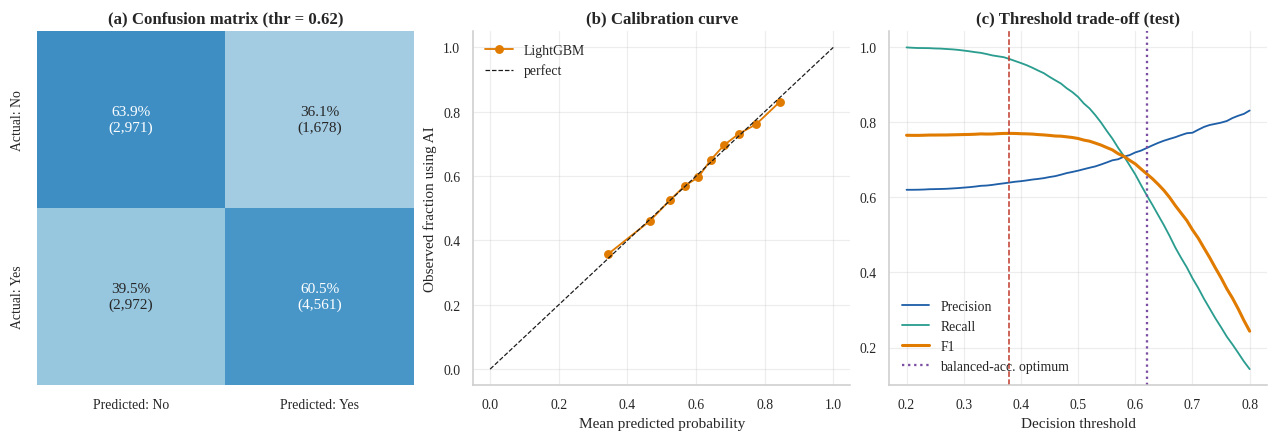

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.9))
cmx = confusion_matrix(y_ate, pt >= thr_bal); cmn = cmx / cmx.sum(1, keepdims=True)
sns.heatmap(cmn, annot=np.array([[f"{cmn[i, j]:.1%}\n({cmx[i, j]:,})" for j in range(2)] for i in range(2)]), fmt="", cmap="Blues", cbar=False, ax=axes[0], xticklabels=["Predicted: No", "Predicted: Yes"], yticklabels=["Actual: No", "Actual: Yes"], vmin=0, vmax=1)
axes[0].set_title(f"(a) Confusion matrix (thr = {thr_bal:.2f})")
fr, mp = calibration_curve(y_ate, pt, n_bins=10, strategy="quantile"); axes[1].plot(mp, fr, "o-", color=PALETTE["orange"], label=best_c_name); axes[1].plot([0, 1], [0, 1], "k--", lw=.8, label="perfect")
axes[1].set_xlabel("Mean predicted probability"); axes[1].set_ylabel("Observed fraction using AI"); axes[1].set_title("(b) Calibration curve"); axes[1].legend()
P_, Rr_, F_ = [], [], []
for t in ths: pr_ = pt >= t; P_.append(precision_score(y_ate, pr_)); Rr_.append(recall_score(y_ate, pr_)); F_.append(f1_score(y_ate, pr_))
axes[2].plot(ths, P_, label="Precision", color=PALETTE["blue"]); axes[2].plot(ths, Rr_, label="Recall", color=PALETTE["green"]); axes[2].plot(ths, F_, label="F1", color=PALETTE["orange"], lw=2)
axes[2].axvline(thr_opt, color=PALETTE["red"], ls="--", lw=1); axes[2].axvline(thr_bal, color=PALETTE["purple"], ls=":", lw=1.5, label="balanced-acc. optimum"); axes[2].set_xlabel("Decision threshold"); axes[2].set_title("(c) Threshold trade-off (test)"); axes[2].legend()
savefig(fig, "fig29_confusion_calibration_threshold", "Selected classifier on the hold-out set: normalised confusion matrix at the balanced-accuracy threshold (a), calibration curve (b) and precision/recall/F1 versus decision threshold (c).", "O7")
plt.show()
R["O7"]["confusion"] = cmx.tolist()
joblib.dump(best_c, MODEL_DIR / "best_ai_adoption_model.joblib"); joblib.dump(fit_c, MODEL_DIR / "all_ai_models.joblib")
json.dump({"threshold_balanced": thr_bal, "threshold_f1": thr_opt, "model": best_c_name}, open(MODEL_DIR / "ai_model_threshold.json", "w"))
save_results()

## O8 — Explainability and error analysis
**Research question.** Which inputs drive the two models, in which direction, and where do the models fail?
**Methods.** (1) *Permutation importance* on the hold-out set: the increase in error when one raw column is randomly
shuffled, $I_j=\text{Err}(\text{shuffled}_j)-\text{Err}(\text{original})$; (2) *SHAP values* (Shapley-value attribution,
$\phi_j=\sum_{S\subseteq F\setminus\{j\}}\frac{|S|!(|F|-|S|-1)!}{|F|!}[f(S\cup j)-f(S)]$) on the LightGBM model, a
gradient-boosting model with performance close to the selected one; (3) *partial dependence* computed by hand so that
derived features are recomputed consistently; (4) *segment-wise error audit*.
**Success:** a ranked list of drivers with uncertainty, and quantified error gaps across countries / segments.

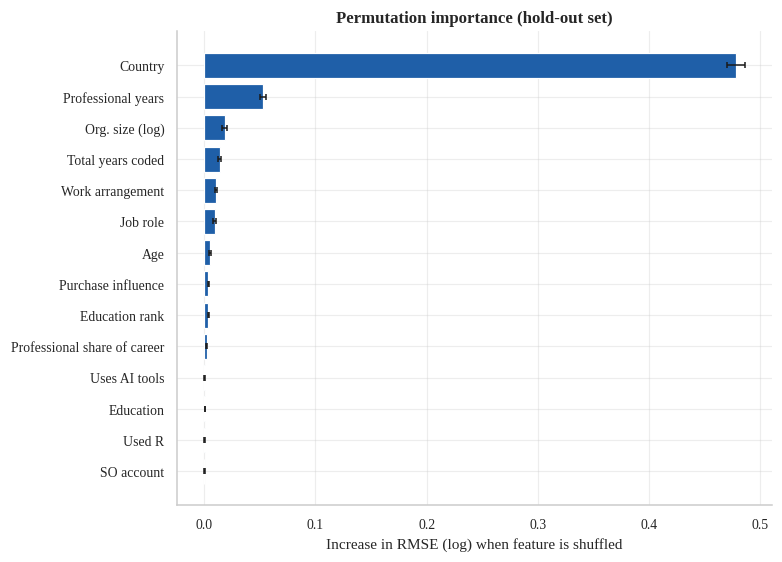

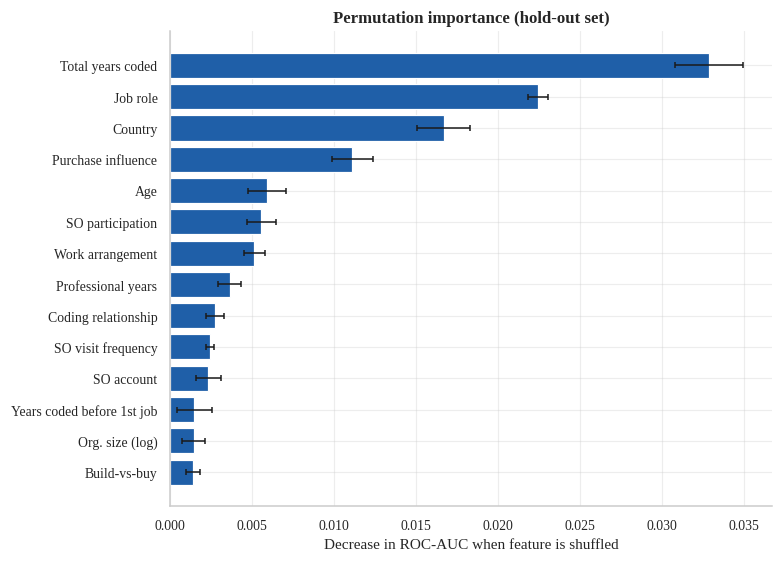

,feature,imp,sd,share_pct
17,country,0.478,0.008,79.590
1,years_code_pro,0.053,0.003,8.828
3,org_log,0.018,0.002,3.072
0,years_code,0.014,0.001,2.308
9,remote_work,0.010,0.001,1.702
18,dev_type,0.009,0.002,1.568
2,age_mid,0.005,0.001,0.923
10,purchase_influence,0.004,0.000,0.629


In [50]:
from sklearn.inspection import permutation_importance
import shap
best_r = joblib.load(MODEL_DIR / "best_salary_model.joblib"); best_c = joblib.load(MODEL_DIR / "best_ai_adoption_model.joblib")
all_r = joblib.load(MODEL_DIR / "all_salary_models.joblib"); all_c = joblib.load(MODEL_DIR / "all_ai_models.joblib")
NICE = {"years_code_pro": "Professional years", "years_code": "Total years coded", "years_pro_sq": "Prof. years²", "country": "Country", "dev_type": "Job role",
        "org_log": "Org. size (log)", "org_short": "Org. size (category)", "ed_rank": "Education rank", "ed_short": "Education", "age_mid": "Age", "remote_work": "Work arrangement",
        "so_visit_rank": "SO visit frequency", "so_part_freq": "SO participation", "so_comm": "SO community", "so_account": "SO account", "exp_gap": "Years coded before 1st job",
        "pro_share": "Professional share of career", "purchase_influence": "Purchase influence", "buildvs_buy": "Build-vs-buy", "r_used": "Used R", "ai_select": "Uses AI tools",
        "main_branch": "Coding relationship"}
def perm_plot(model, X, y, scoring, title, fname, caption, obj, sign=1, n_repeats=5):
    pi = permutation_importance(model, X, y, scoring=scoring, n_repeats=n_repeats, random_state=RANDOM_STATE, n_jobs=1)
    d = pd.DataFrame({"feature": X.columns, "imp": sign * pi.importances_mean, "sd": pi.importances_std}).sort_values("imp", ascending=False)
    d["share_pct"] = d.imp.clip(lower=0) / d.imp.clip(lower=0).sum() * 100
    fig, ax = plt.subplots(figsize=(7.0, 5.0)); t = d.head(14).iloc[::-1]
    ax.barh(t.feature.map(lambda c: NICE.get(c, c)), t.imp, xerr=t.sd, color=PALETTE["blue"], error_kw=dict(capsize=2, lw=1))
    ax.set_xlabel(title); ax.set_title("Permutation importance (hold-out set)")
    savefig(fig, fname, caption, obj); plt.show(); return d
imp_r = perm_plot(best_r, X_te, y_te, "neg_root_mean_squared_error", "Increase in RMSE (log) when feature is shuffled", "fig30_perm_importance_salary",
                  f"Permutation importance for the selected salary model ({R['O6']['best']}).", "O8")
imp_c = perm_plot(best_c, X_ate, y_ate, "roc_auc", "Decrease in ROC-AUC when feature is shuffled", "fig31_perm_importance_ai",
                  f"Permutation importance for the selected AI-adoption model ({R['O7']['best']}).", "O8", n_repeats=5)
save_table(imp_r.round(4), "tbl_o8_perm_importance_salary", "Permutation importance of raw predictors - salary model", "O8"); save_table(imp_c.round(4), "tbl_o8_perm_importance_ai", "Permutation importance of raw predictors - AI-adoption model", "O8")
R["O8"] = dict(salary_top=imp_r.head(8).round(4).to_dict("records"), ai_top=imp_c.head(8).round(4).to_dict("records"),
               salary_top3_share=float(imp_r.head(3).share_pct.sum()), ai_top3_share=float(imp_c.head(3).share_pct.sum()))
imp_r.head(8).round(4)

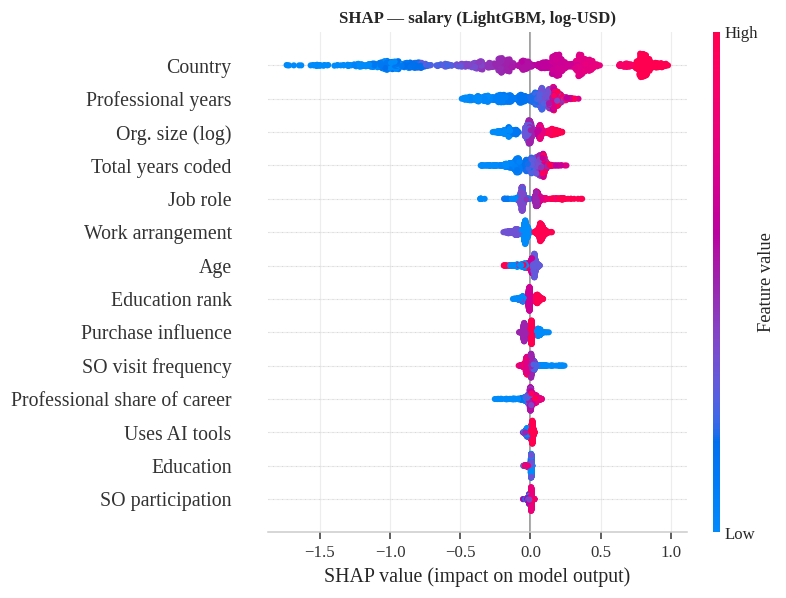

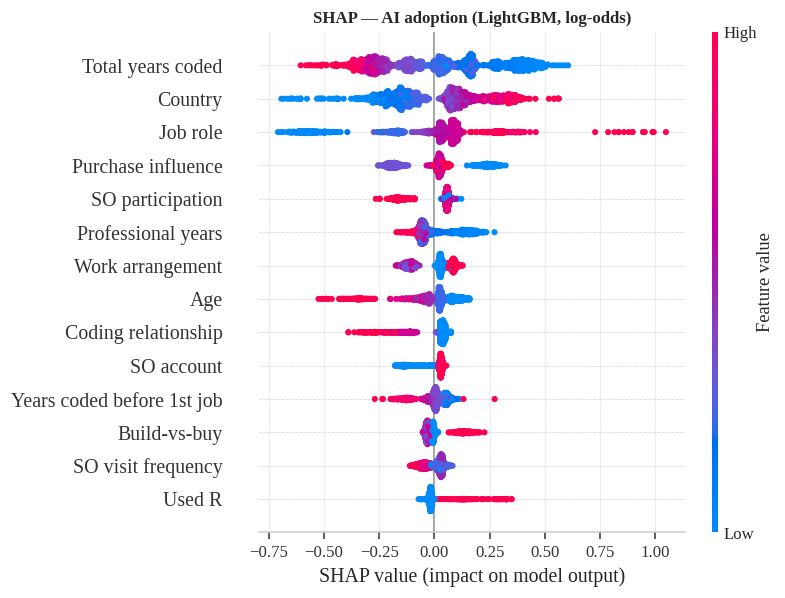

,feature,mean_abs_shap
26,Country,0.545
1,Professional years,0.164
3,Org. size (log),0.081
0,Total years coded,0.079
27,Job role,0.070
16,Work arrangement,0.067


In [51]:
# SHAP on LightGBM (tree SHAP is exact and fast for tree ensembles) --------------------------------------------------
def shap_plot(pipe, X, fname, caption, title, n=1500):
    Xs = X.sample(n, random_state=RANDOM_STATE); pre, mdl = pipe[:-1], pipe[-1]
    Xt = pd.DataFrame(pre.transform(Xs), columns=pre.get_feature_names_out())
    Xt.columns = [NICE.get(c, c.replace("missingindicator_", "missing: ")) for c in Xt.columns]
    sv = shap.TreeExplainer(mdl).shap_values(Xt)
    sv = sv[1] if isinstance(sv, list) else sv
    plt.figure(figsize=(7.4, 5.4), layout="none"); shap.summary_plot(sv, Xt, max_display=14, show=False, plot_size=None)
    fig = plt.gcf(); fig.axes[0].set_title(title); fig.axes[0].set_xlabel("SHAP value (impact on model output)")
    savefig(fig, fname, caption, "O8"); plt.show()
    imp = pd.DataFrame({"feature": Xt.columns, "mean_abs_shap": np.abs(sv).mean(0)}).sort_values("mean_abs_shap", ascending=False)
    return imp, sv, Xt
shap_r, sv_r, Xt_r = shap_plot(all_r["LightGBM"], X_te, "fig32_shap_salary", "SHAP summary of the LightGBM salary model: each dot is a respondent; colour = feature value; x = effect on predicted log-compensation.", "SHAP — salary (LightGBM, log-USD)")
shap_c, sv_c, Xt_c = shap_plot(all_c["LightGBM"], X_ate, "fig33_shap_ai", "SHAP summary of the LightGBM AI-adoption model (effect on log-odds of using AI).", "SHAP — AI adoption (LightGBM, log-odds)")
R["O8"]["shap_salary_top"] = shap_r.head(8).round(4).to_dict("records"); R["O8"]["shap_ai_top"] = shap_c.head(8).round(4).to_dict("records")
shap_r.head(6).round(4)

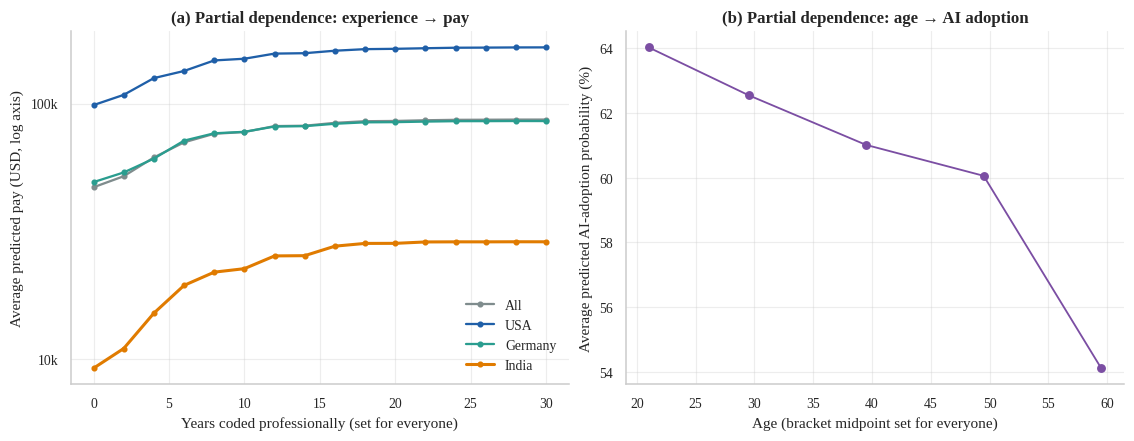

In [52]:
# Partial dependence (computed manually so derived experience features stay consistent) ------------------------------
def pdp_experience(model, Xbase, grid, mask=None):
    out = []
    Xb = Xbase if mask is None else Xbase[mask]
    for g in grid:
        Xg = Xb.copy(); Xg["years_code_pro"] = float(g); Xg["years_pro_sq"] = float(g) ** 2
        Xg["exp_gap"] = Xg["years_code"] - g; Xg["pro_share"] = g / Xg["years_code"].where(Xg["years_code"] > 0)
        out.append(np.exp(model.predict(Xg)).mean())          # average predicted USD
    return np.array(out)
grid = np.arange(0, 31, 2)
fig, axes = plt.subplots(1, 2, figsize=(10.2, 3.9))
for c, col in [("All", PALETTE["grey"]), ("USA", PALETTE["blue"]), ("Germany", PALETTE["green"]), ("India", PALETTE["orange"])]:
    mask = None if c == "All" else (X_te.country == c).values
    axes[0].plot(grid, pdp_experience(best_r, X_te, grid, mask), "o-", ms=3, color=col, label=c, lw=2 if c == "India" else 1.5)
axes[0].set_yscale("log"); axes[0].set_xlabel("Years coded professionally (set for everyone)"); axes[0].set_ylabel("Average predicted pay (USD, log axis)")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:.0f}k")); axes[0].set_title("(a) Partial dependence: experience → pay"); axes[0].legend()
ages_g = np.array([21, 29.5, 39.5, 49.5, 59.5])
pd_age = []
for g in ages_g:
    Xg = X_ate.copy(); Xg["age_mid"] = g; pd_age.append(best_c.predict_proba(Xg)[:, 1].mean() * 100)
axes[1].plot(ages_g, pd_age, "o-", color=PALETTE["purple"]); axes[1].set_xlabel("Age (bracket midpoint set for everyone)"); axes[1].set_ylabel("Average predicted AI-adoption probability (%)"); axes[1].set_title("(b) Partial dependence: age → AI adoption")
savefig(fig, "fig34_partial_dependence", "Partial dependence: average predicted pay as professional experience is varied, by country (a); average predicted AI-adoption probability as age is varied (b).", "O8")
plt.show()
R["O8"]["pdp_exp"] = {c: pdp_experience(best_r, X_te, np.array([0, 5, 10, 20, 30]), None if c == "All" else (X_te.country == c).values).round(0).tolist() for c in ["All", "USA", "India", "Germany"]}
R["O8"]["pdp_age"] = dict(zip(ages_g.tolist(), np.round(pd_age, 2).tolist()))

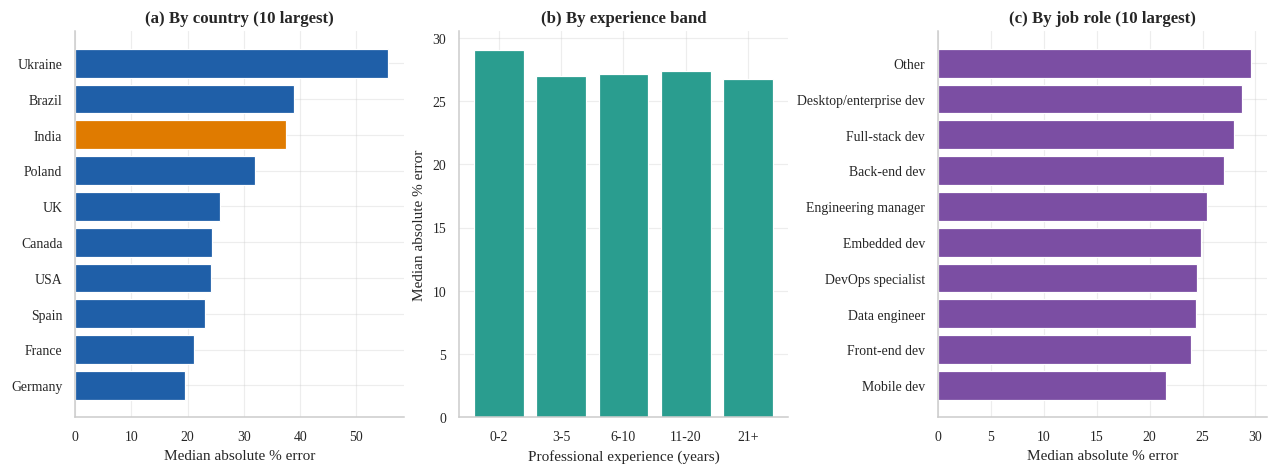

,n,MdAPE_pct,MAE_USD,bias_log,within25
country,,,,,
USA,842,24.110,"54,842.110",0.010,51.660
Germany,351,19.450,"21,424.710",0.030,59.540
UK,254,25.810,"29,457.530",-0.040,48.030
Ukraine,236,55.690,"24,993.280",0.120,14.830
India,193,37.440,"14,246.290",0.080,31.610
France,168,21.120,"18,521.850",0.020,55.950
Canada,160,24.410,"30,099.840",-0.000,50.000
Brazil,124,38.890,"17,285.620",-0.120,33.870


In [53]:
# ---- Error audit: salary model -----------------------------------------------------------------------------------------
te = cohort.loc[X_te.index].copy(); te["pred_log"] = best_r.predict(X_te); te["resid"] = te.log_comp - te.pred_log
te["pred_usd"] = np.exp(te.pred_log); te["ape"] = (te.pred_usd - te.converted_comp_yearly).abs() / te.converted_comp_yearly; te["ae_usd"] = (te.pred_usd - te.converted_comp_yearly).abs()
def seg(col, keep=None, minn=40):
    g = te.groupby(col).agg(n=("ape", "size"), MdAPE_pct=("ape", lambda s: s.median() * 100), MAE_USD=("ae_usd", "mean"), bias_log=("resid", "mean"), within25=("ape", lambda s: (s <= .25).mean() * 100))
    g = g[g.n >= minn]; return g.sort_values("n", ascending=False)
seg_c = seg("country"); seg_e = seg("exp_band", minn=40).reindex(bands); seg_r = seg("dev_type", minn=60).head(10)
save_table(seg_c.round(3).reset_index().head(12), "tbl_o8_error_by_country", "Salary-model error by country (hold-out, n >= 40)", "O8")
ind_te, rest_te = te[te.country == "India"], te[te.country != "India"]
R["O8"]["error"] = dict(overall_mdape=float(te.ape.median() * 100), overall_mae=float(te.ae_usd.mean()), india_mdape=float(ind_te.ape.median() * 100), india_mae=float(ind_te.ae_usd.mean()), india_n=len(ind_te),
                        rest_mdape=float(rest_te.ape.median() * 100), usa_mdape=float(te[te.country == "USA"].ape.median() * 100), india_bias=float(ind_te.resid.mean()),
                        by_country=seg_c.round(3).reset_index().head(10).to_dict("records"), by_exp=seg_e.round(3).reset_index().to_dict("records"), by_role=seg_r.round(3).reset_index().to_dict("records"))
fig, axes = plt.subplots(1, 3, figsize=(11.5, 4.2))
t = seg_c.head(10).sort_values("MdAPE_pct"); axes[0].barh(t.index, t.MdAPE_pct, color=[PALETTE["orange"] if c == "India" else PALETTE["blue"] for c in t.index]); axes[0].set_xlabel("Median absolute % error"); axes[0].set_title("(a) By country (10 largest)")
t = seg_e; axes[1].bar(t.index, t.MdAPE_pct, color=PALETTE["green"]); axes[1].set_xlabel("Professional experience (years)"); axes[1].set_ylabel("Median absolute % error"); axes[1].set_title("(b) By experience band")
t = seg_r.sort_values("MdAPE_pct"); axes[2].barh(t.index, t.MdAPE_pct, color=PALETTE["purple"]); axes[2].set_xlabel("Median absolute % error"); axes[2].set_title("(c) By job role (10 largest)")
savefig(fig, "fig35_salary_error_by_segment", "Hold-out error of the salary model by country (a), experience band (b) and job role (c); India highlighted in orange.", "O8")
plt.show()
worst = te.assign(err_usd=te.pred_usd - te.converted_comp_yearly).sort_values("ae_usd", ascending=False).head(8)[["country", "dev_type", "years_code_pro", "org_short", "converted_comp_yearly", "pred_usd", "err_usd"]].round(0)
save_table(worst, "tbl_o8_worst_predictions", "The eight largest salary-prediction errors on the hold-out set", "O8"); R["O8"]["worst"] = worst.to_dict("records")
seg_c.head(8).round(2)

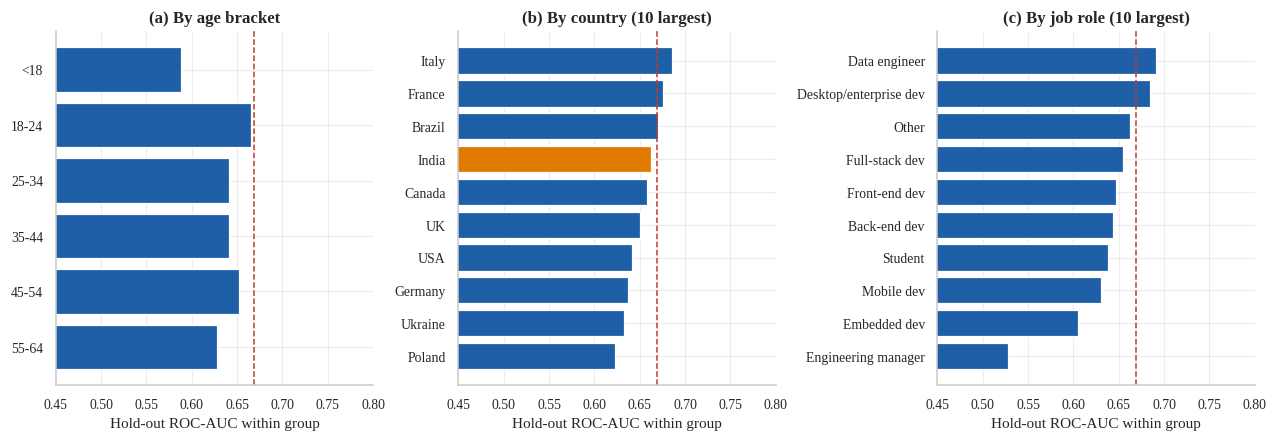

,group,n,accuracy,auc,pos_rate,pred_rate
15,USA,2226,55.800,0.640,55.350,28.750
5,Germany,959,57.460,0.640,57.870,40.350
6,India,805,67.700,0.660,67.080,79.500
14,UK,668,58.080,0.650,50.450,22.600
16,Ukraine,541,69.690,0.630,70.980,83.550
4,France,423,59.100,0.680,53.430,29.550
3,Canada,410,60.000,0.660,56.590,40.490
9,Poland,322,59.320,0.620,61.800,57.760
7,Italy,298,56.040,0.690,60.740,32.890
2,Brazil,292,66.100,0.670,66.780,63.700


In [54]:
# ---- Error audit: AI-adoption model ------------------------------------------------------------------------------------------
ta = ai_cohort.loc[X_ate.index].copy(); ta["p"] = best_c.predict_proba(X_ate)[:, 1]; ta["pred"] = (ta.p >= R["O7"]["threshold_bal"]).astype(int); ta["ok"] = (ta.pred == ta.uses_ai)
def cseg(col, minn=300, keep=None):
    rows = []
    for k, g in ta.groupby(col):
        if len(g) >= minn and g.uses_ai.nunique() == 2: rows.append(dict(group=k, n=len(g), accuracy=g.ok.mean() * 100, auc=roc_auc_score(g.uses_ai, g.p), pos_rate=g.uses_ai.mean() * 100, pred_rate=g.pred.mean() * 100))
    return pd.DataFrame(rows)
cs_age = cseg("age"); cs_age = cs_age[cs_age.group != "Prefer not to say"].set_index("group").reindex([a for a in AGE_ORDER if a in set(cs_age.group)]).reset_index()
cs_c = cseg("country", 150).sort_values("n", ascending=False).head(10); cs_r = cseg("dev_type", 150).sort_values("n", ascending=False).head(10)
R["O8"]["clf_error"] = dict(by_age=cs_age.round(2).to_dict("records"), by_country=cs_c.round(2).to_dict("records"), by_role=cs_r.round(2).to_dict("records"),
                            india=cseg("country", 100).query("group == 'India'").round(2).to_dict("records"))
save_table(cs_c.round(2), "tbl_o8_clf_error_country", "AI-adoption model: hold-out accuracy and AUC by country", "O8")
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.9))
for ax, d_, title in [(axes[0], cs_age, "(a) By age bracket"), (axes[1], cs_c.sort_values("auc"), "(b) By country (10 largest)"), (axes[2], cs_r.sort_values("auc"), "(c) By job role (10 largest)")]:
    cols = [PALETTE["orange"] if g == "India" else PALETTE["blue"] for g in d_.group]
    ax.barh(d_.group, d_.auc, color=cols); ax.axvline(R["O7"]["metrics_at_05"]["ROC_AUC"], color=PALETTE["red"], ls="--", lw=1); ax.set_xlim(.45, .8); ax.set_xlabel("Hold-out ROC-AUC within group"); ax.set_title(title)
    if ax is axes[0]: ax.invert_yaxis()
savefig(fig, "fig36_ai_error_by_segment", "Hold-out ROC-AUC of the AI-adoption classifier within age brackets (a), countries (b) and roles (c); dashed line = overall AUC.", "O8")
plt.show(); cs_c.round(2)

In [55]:
# Demonstration of the saved models on two contrasting developer profiles -----------------------------------------------
from src.predict import predict_salary, predict_ai_adoption
profiles = {"Mid-level full-stack dev, India": dict(country="India", years_code=9, years_code_pro=5, age="25-34", dev_type="Full-stack dev"),
            "Mid-level full-stack dev, USA": dict(country="USA", years_code=9, years_code_pro=5, age="25-34", dev_type="Full-stack dev"),
            "Senior engineering manager, Germany": dict(country="Germany", years_code=22, years_code_pro=18, age="35-44", dev_type="Engineering manager", org_short="1,000 to 4,999", ed_short="Master's"),
            "Student-age Python learner, Brazil": dict(country="Brazil", years_code=3, years_code_pro=0, age="18-24", dev_type="Student", main_branch="I am learning to code", ed_short="Some college")}
demo = pd.DataFrame([dict(profile=k, predicted_salary_usd=round(predict_salary(v, best_r), -2), p_uses_ai=round(predict_ai_adoption(v, best_c), 3)) for k, v in profiles.items()])
save_table(demo, "tbl_demo_predictions", "Example predictions of the saved models for illustrative profiles", "O8"); R["demo"] = demo.to_dict("records"); save_results(); demo

,profile,predicted_salary_usd,p_uses_ai
0,"Mid-level full-stack dev, India","18,000.000",0.704
1,"Mid-level full-stack dev, USA","115,700.000",0.626
2,"Senior engineering manager, Germany","124,300.000",0.523
3,"Student-age Python learner, Brazil","4,600.000",0.785


# Part G — Conclusions: objective-to-evidence map

In [56]:
o = R
rows = [
 ("O1", "Country explains pay", f"Country alone explains R² = {o['O1']['R2_country_all']:.2f} of log-pay variance (η² = {o['O1']['eta2_top']:.2f} among the 28 largest countries); India's median USD {o['O1']['india_median']:,.0f} is {o['O1']['india_usa_ratio']:.2f}× the USA median (95 % CI {o['O1']['india_usa_ratio_ci'][0]:.2f}–{o['O1']['india_usa_ratio_ci'][1]:.2f})", "fig09, fig10"),
 ("O2", "Experience premium", f"Spearman ρ = {o['O2']['spearman_all']['rho']:.2f}; ≈ {o['O2']['marginal'][0]['pct_per_year']:.1f} % per extra year at entry, flattening at ≈ {o['O2']['peak_years']:.0f} yrs; India's early-career slope is steeper (interaction p {fmt_p(o['O2']['interaction_linear']['p'])})", "fig11, fig12"),
 ("O3", "Net effects", f"Adding role, company size, work mode and education lifts R² from {o['O3']['nested'][1]['R2']:.3f} to {o['O3']['nested'][-1]['R2']:.3f}; remote work +{[a for a in o['O3']['adj'] if a['term']=='Remote'][0]['pct']:.0f} % vs in-person after adjustment", "fig13–fig15"),
 ("O4", "AI adoption landscape", f"{o['O4']['overall_rate']:.1f} % use AI; adoption falls with age/experience; India {o['O4']['india']['rate']:.1f} % vs rest {o['O4']['india']['rest_rate']:.1f} %", "fig16–fig19"),
 ("O5", "AI attitudes", f"{o['O5']['fav_pct']:.0f} % favourable but only {o['O5']['trust_positive_pct']:.0f} % trust accuracy; {o['O5']['threat_yes_pct']:.0f} % see AI as a job threat; experience effects are tiny (|ρ| < 0.06)", "fig20–fig23"),
 ("O6", "Salary prediction", f"Best: {o['O6']['best']}; test R² = {[c for c in o['O6']['comparison'] if c['model']==o['O6']['best']][0]['test_R2']:.3f}; RMSE(log) cut by {o['O6']['rmse_reduction_vs_global_pct']:.1f} % vs baseline", "fig24–fig26"),
 ("O7", "AI-adoption prediction", f"Best: {o['O7']['best']}; test ROC-AUC = {o['O7']['metrics_at_05']['ROC_AUC']:.3f}, balanced accuracy = {o['O7']['metrics_at_bal']['BalAcc']:.3f} at threshold {o['O7']['threshold_bal']:.2f}", "fig27–fig29"),
 ("O8", "Explainability & errors", f"Top salary drivers: {', '.join(NICE.get(d['feature'], d['feature']) for d in o['O8']['salary_top'][:3])}; India MdAPE {o['O8']['error']['india_mdape']:.0f} % vs USA {o['O8']['error']['usa_mdape']:.0f} %", "fig30–fig36"),
]
summary = pd.DataFrame(rows, columns=["objective", "topic", "headline result (computed from this notebook's own outputs)", "figures"])
save_table(summary, "tbl_objective_mapping", "Objective-to-evidence mapping with headline results", "All")
pd.set_option("display.max_colwidth", 220); print(summary.to_string(index=False))
R["success"] = {k: R["O6"][k] for k in ("success_rmse_cut_40", "success_beats_country_median")} | {k: R["O7"][k] for k in ("success_auc_065", "success_f1_at_05", "success_f1_at_opt")}
save_results()
print("\nPre-registered success criteria:", json.dumps(R["success"], indent=1))
print("Figures:", len(list(FIG_DIR.glob("*.png"))), "| tables:", len(list((RES_DIR / "tables").glob("*.csv"))))

objective                   topic                                                                                                            headline result (computed from this notebook's own outputs)      figures
       O1    Country explains pay Country alone explains R² = 0.51 of log-pay variance (η² = 0.49 among the 28 largest countries); India's median USD 17,945 is 0.12× the USA median (95 % CI 0.11–0.13) fig09, fig10
       O2      Experience premium                              Spearman ρ = 0.48; ≈ 9.2 % per extra year at entry, flattening at ≈ 24 yrs; India's early-career slope is steeper (interaction p < 0.001) fig11, fig12
       O3             Net effects                                       Adding role, company size, work mode and education lifts R² from 0.540 to 0.574; remote work +29 % vs in-person after adjustment  fig13–fig15
       O4   AI adoption landscape                                                                                         61.8 % use AI; adoptio